# Forecasting next-day volatility of Commercial Bank of Ceylon (COMB.N0000)
## Traditional time-series models vs machine learning — CSE daily data, Jan 2024 – Dec 2025

**Research question.** *How accurately can the next trading day's price volatility of COMB voting shares be forecast
using traditional time-series models (ARIMA on log-volatility, GARCH) compared with machine-learning models
(Ridge regression, Random Forest, Gradient Boosting), relative to simple baselines, when evaluated one day ahead on an
untouched final period (Aug–Dec 2025) — and does the answer change between calm and turbulent market conditions?*

This notebook runs the complete analysis step by step. Every function lives in `src/` so that `python main.py`
produces exactly the same numbers. Run cells from top to bottom (Kernel → Restart & Run All).

In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

from src import config, data_processing as dp, feature_engineering as fe
from src import exploratory_analysis as eda, diagnostics as dg, additional_analysis as aa
from src.pipeline import run_models
show = lambda p: display(Image(filename=str(p), width=950))

## 1. Inspect the raw dataset
**What we did and why.** Before choosing any method we looked at what the file actually contains. It turned out to mix
*three different securities*: voting shares (N), non-voting shares (X) and rights entitlements (R) that traded only for six days
during the 2024 rights issue. Treating them as one series would be a serious error.

In [2]:
raw = dp.load_raw()
print("Raw shape:", raw.shape)
display(raw.head())
display(dp.raw_overview(raw))

Raw shape: (968, 12)


,company,share_class,sub_type,name,date,high,low,close,open,trades,volume,turnover
0,COMB,N,0,COMMERCIAL BANK,2024-01-02,98.0000,94.5000,96.9000,95.5000,218,120591,"11,587,528.8000"
1,COMB,N,0,COMMERCIAL BANK,2024-01-03,97.5000,95.7000,95.9000,96.0000,144,218632,"20,992,986.9000"
2,COMB,N,0,COMMERCIAL BANK,2024-01-04,96.0000,95.2000,95.5000,96.0000,86,377339,"36,051,604.1000"
3,COMB,N,0,COMMERCIAL BANK,2024-01-05,96.2000,95.0000,95.2000,96.2000,92,238327,"22,689,253.1000"
4,COMB,N,0,COMMERCIAL BANK,2024-01-08,95.5000,94.0000,95.0000,95.2000,115,351582,"33,402,491.3000"


,share_class,sub_type,rows,start,end,meaning
0,N,0,478,2024-01-02,2025-12-31,Ordinary voting share (COMB.N0000)
1,R,0,6,2024-07-30,2024-08-06,Rights entitlement (traded 30 Jul-6 Aug 2024)
2,R,1,6,2024-07-30,2024-08-06,Rights entitlement (traded 30 Jul-6 Aug 2024)
3,X,0,478,2024-01-02,2025-12-31,Ordinary non-voting share (COMB.X0000)


### Data-quality checks (voting share)
**Key findings.** No duplicates, chronological order, no impossible prices. Four LOW and two OPEN values are missing (2024).
**The OPEN column equals CLOSE on 100% of days in 2025** — it is not a real opening price in this export, so we never use it.
Gaps of 2–5 calendar days are weekends and CSE holidays, not missing data.

In [3]:
display(dp.quality_report(raw, "N"))

,check,result
0,Rows (trading days),478
1,First date,2024-01-02
2,Last date,2025-12-31
3,Sorted chronologically,True
4,Duplicate dates,0
5,Missing HIGH,0
6,Missing LOW,4
7,Missing OPEN,2
8,Missing CLOSE,0
9,Zero / negative prices,0


## 2. Cleaning, corporate actions and the target
**What we did and why.**
* Missing LOW prices were filled with min(open, close) of the *same* day (no future information).
* Unadjusted closing prices drop mechanically on ex-dividend and ex-rights days. We corrected the close-to-close returns on
  those three dates (dividend added back; rights issue via the theoretical ex-rights price).
* **Target:** the Parkinson range-based daily volatility, σ = 100·|ln(High/Low)| / √(4 ln 2). It uses the whole day's
  trading range, so it measures daily risk much more precisely than one squared return, and it is unaffected by dividends.

In [4]:
g = dp.build_dataset("N")
g_x = dp.build_dataset("X")
display(dp.corporate_action_table(g, "N"))
display(g[["high","low","close","volume","ret","park_vol"]].head())

,date,type,note,raw_return_%,adjusted_return_%
0,2024-04-01,dividend,FY2023 final dividend (DPS Rs 6.50; cash/scrip...,-3.3300,3.3220
1,2024-07-16,rights,1-for-5 rights issue at Rs 85 (ex-rights date ...,-3.6540,-0.4950
2,2025-04-01,dividend,"FY2024 dividend Rs 7.50 cash + Rs 2.00 scrip, ...",-2.5750,3.8240


,high,low,close,volume,ret,park_vol
date,,,,,,
2024-01-02,98.0000,94.5000,96.9000,120591,NaN,2.1841
2024-01-03,97.5000,95.7000,95.9000,218632,-1.0374,1.1191
2024-01-04,96.0000,95.2000,95.5000,377339,-0.4180,0.5026
2024-01-05,96.2000,95.0000,95.2000,238327,-0.3146,0.7539
2024-01-08,95.5000,94.0000,95.0000,351582,-0.2103,0.9508


## 3. Exploratory data analysis

In [5]:
display(eda.descriptive_stats(g))
display(eda.period_stats(g))

,n,mean,std,min,median,max,skewness,excess kurtosis
variable,,,,,,,,
Close price (Rs.),478,136.2872,39.1356,79.8000,136.3750,216.7500,0.4761,-0.9913
Adjusted daily log return (%),477,0.1867,1.5920,-8.9729,0.0000,8.9780,-0.0537,6.5648
Parkinson daily volatility (%),478,1.2108,0.9362,0.1402,0.9376,11.2432,3.8533,29.6155
Share volume (No.),478,"936,696.0439","2,028,872.6478","4,764.0000","440,246.5000","29,080,805.0000",9.6525,119.7614


,days,price change (%),mean return (%/day),std return (%/day),mean Parkinson vol (%),median Parkinson vol (%),annualised vol (%)
period,,,,,,,
2024,240,49.3808,0.2090,1.5908,1.2681,1.0471,24.7476
2025,238,37.5000,0.1643,1.5962,1.1531,0.8472,24.8309
Training period,277,53.2508,0.1902,1.5827,1.2662,1.0405,24.6205
Validation period,99,16.6667,0.1997,1.9326,1.2919,0.9031,30.0646
Test period,102,15.3736,0.1644,1.2246,0.9820,0.7245,19.0503


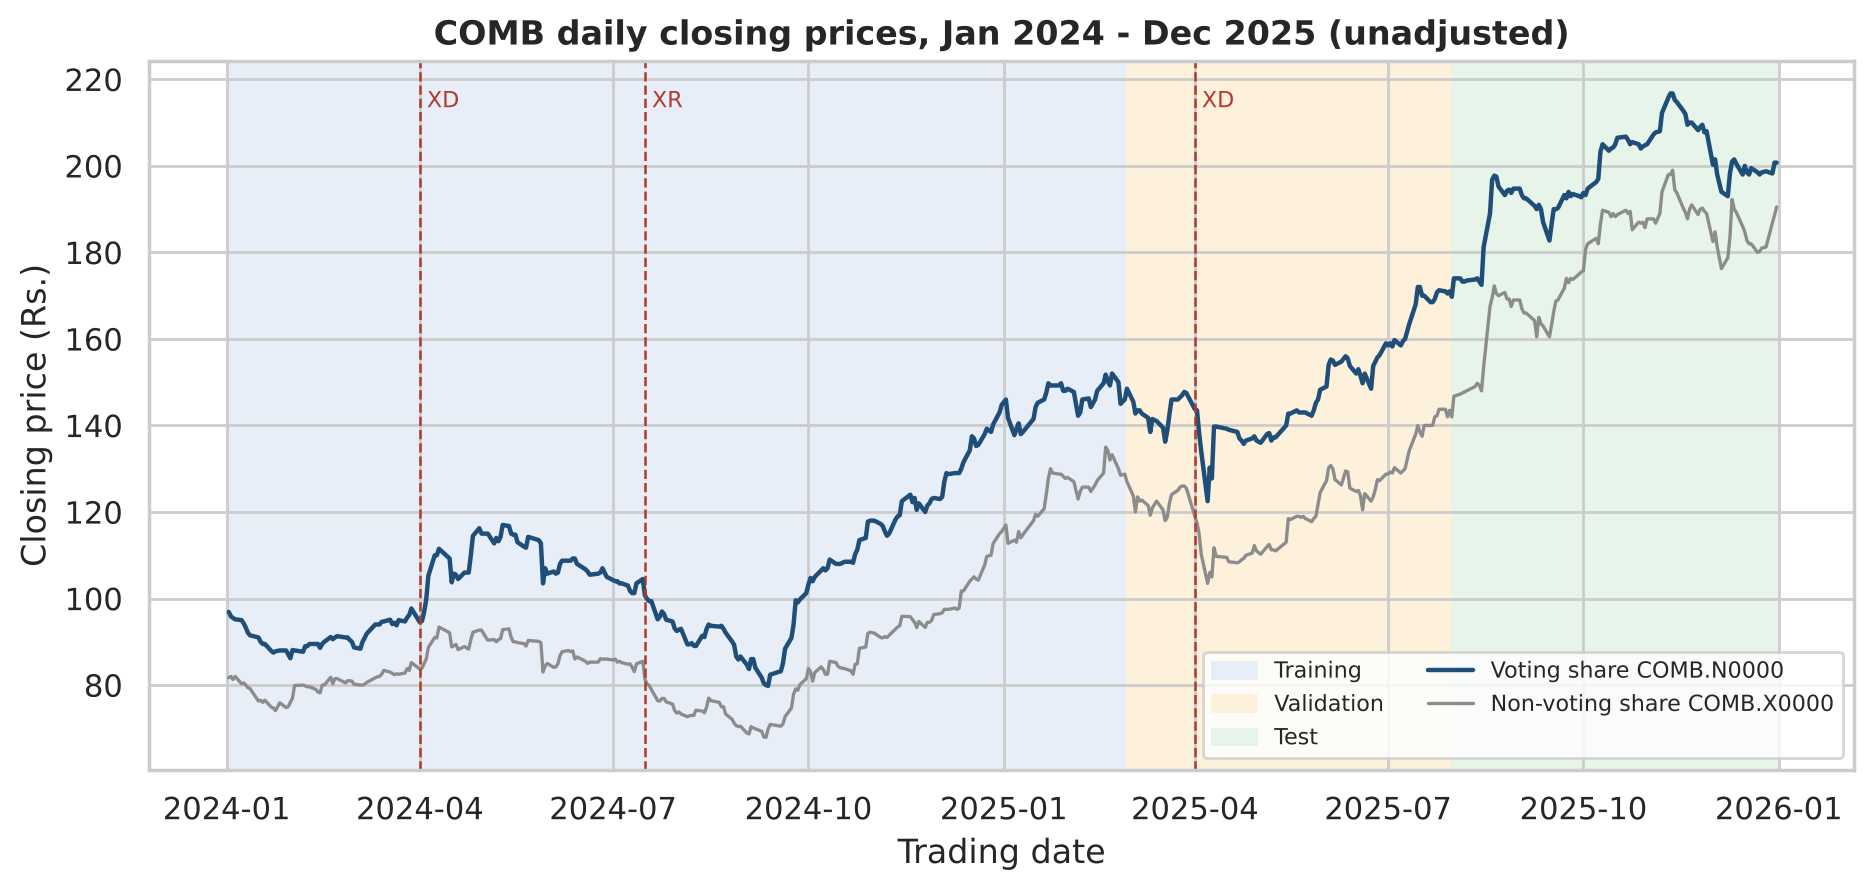

In [6]:
show(eda.fig_price_history(g, g_x))

**Interpretation.** The voting share rose from about Rs 97 to Rs 201 (unadjusted) — a strong bull market for Sri Lankan banks.
The red lines mark the ex-dividend (XD) and ex-rights (XR) days that we corrected for. A rising price level is non-stationary,
which is one reason we do not forecast the price itself.

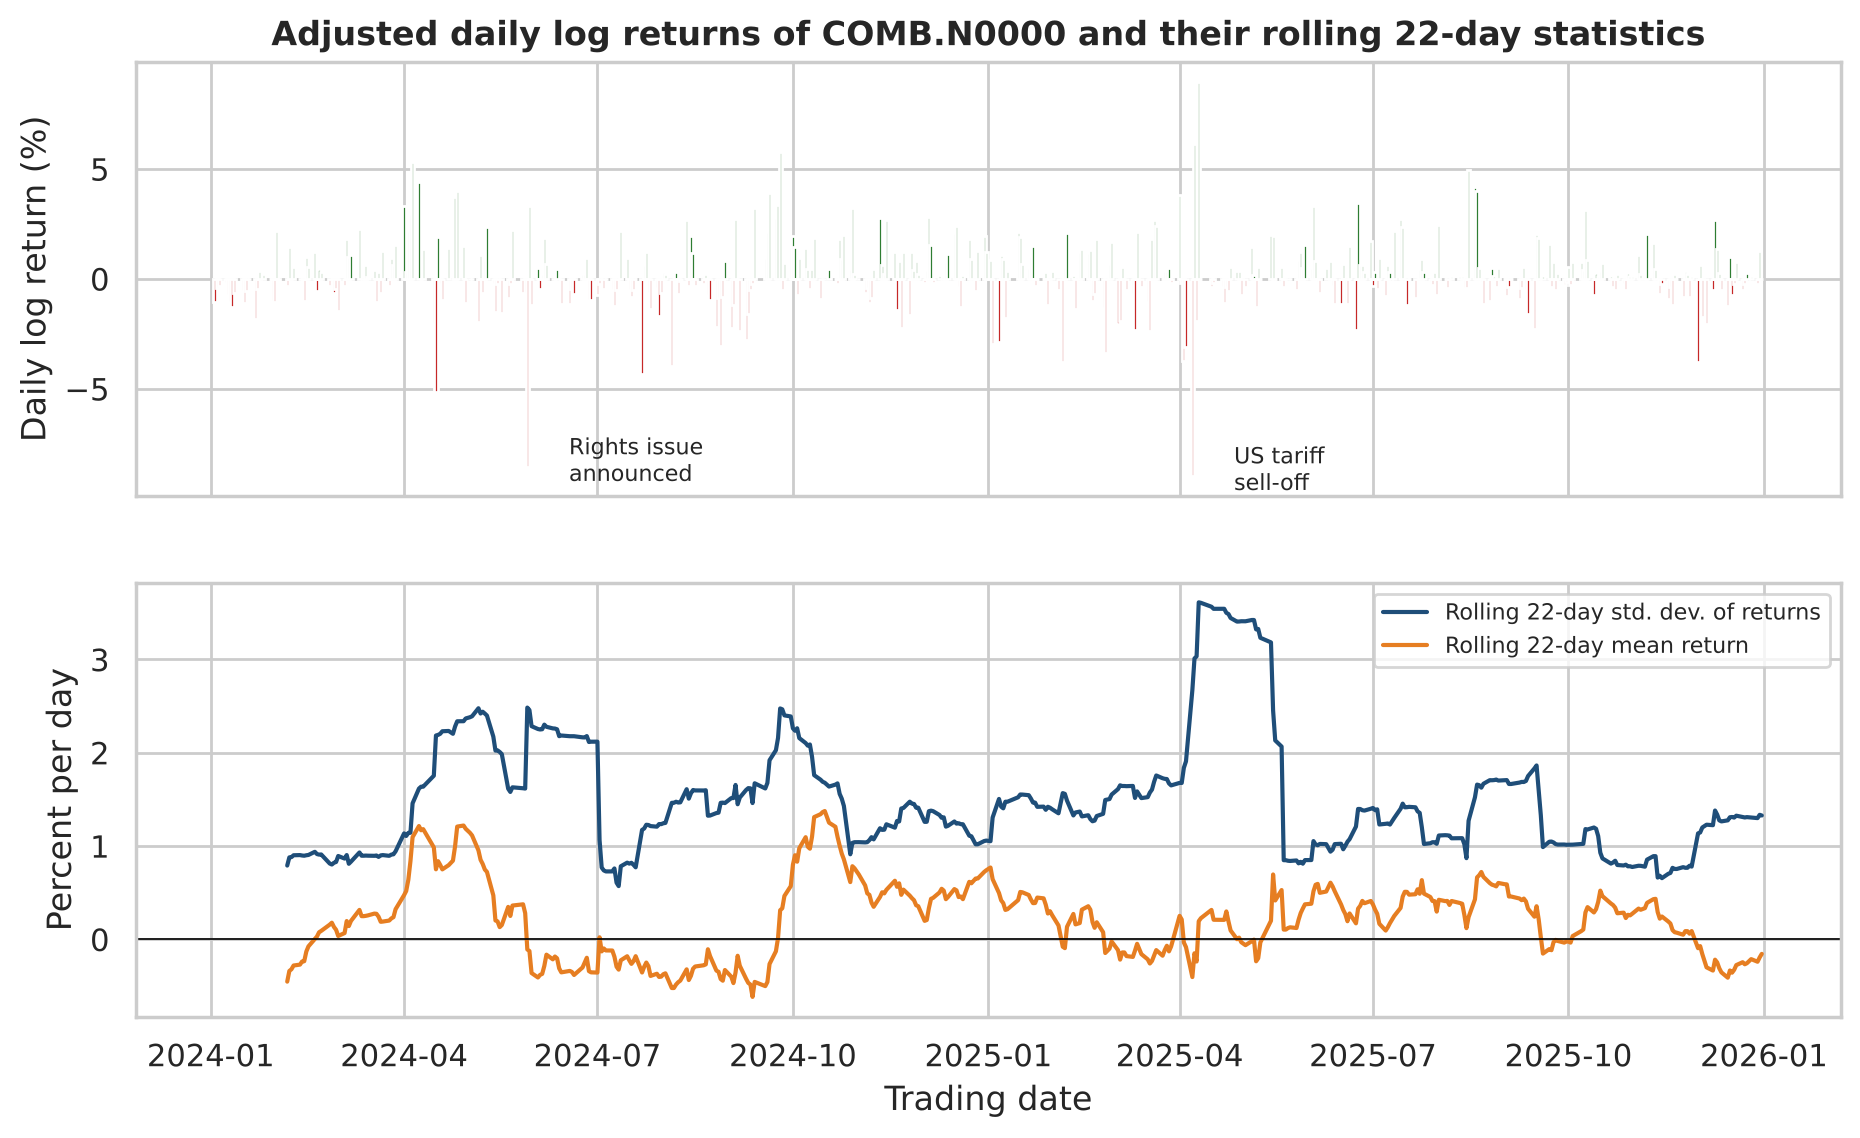

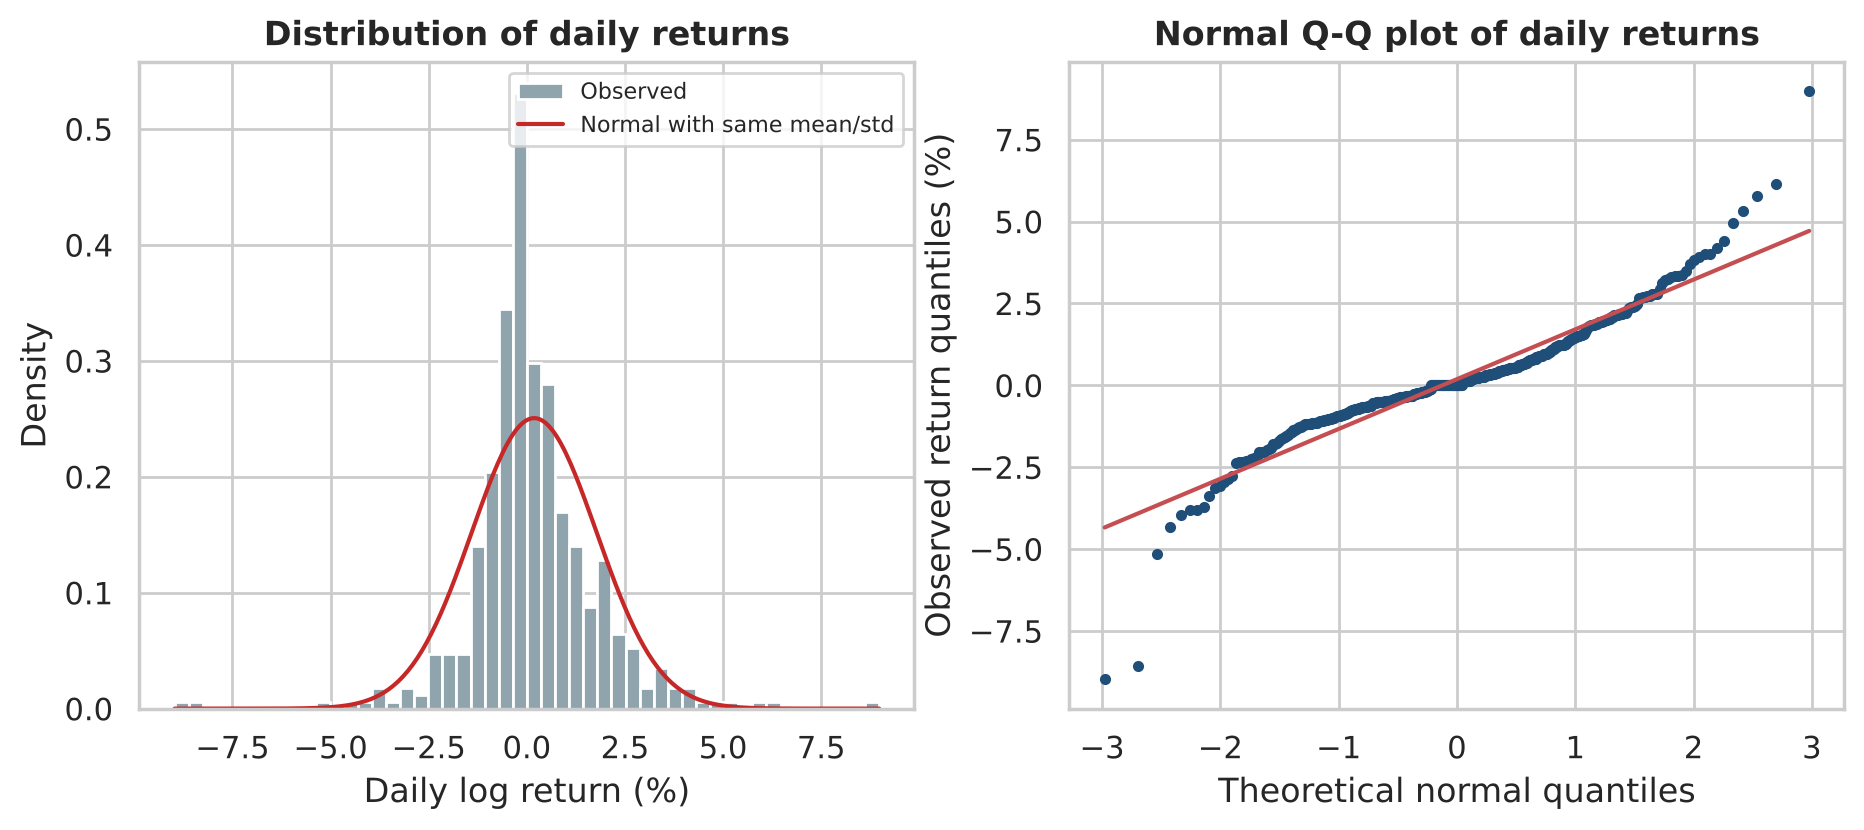

In [7]:
show(eda.fig_returns(g)); show(eda.fig_return_distribution(g))

**Interpretation.** Returns show bursts of large moves (the rights-issue announcement in May 2024, the US-tariff sell-off of April 2025),
fat tails (Jarque–Bera rejects normality) and a rolling standard deviation that changes over time — i.e. *risk itself varies*.
This motivates forecasting volatility rather than returns.

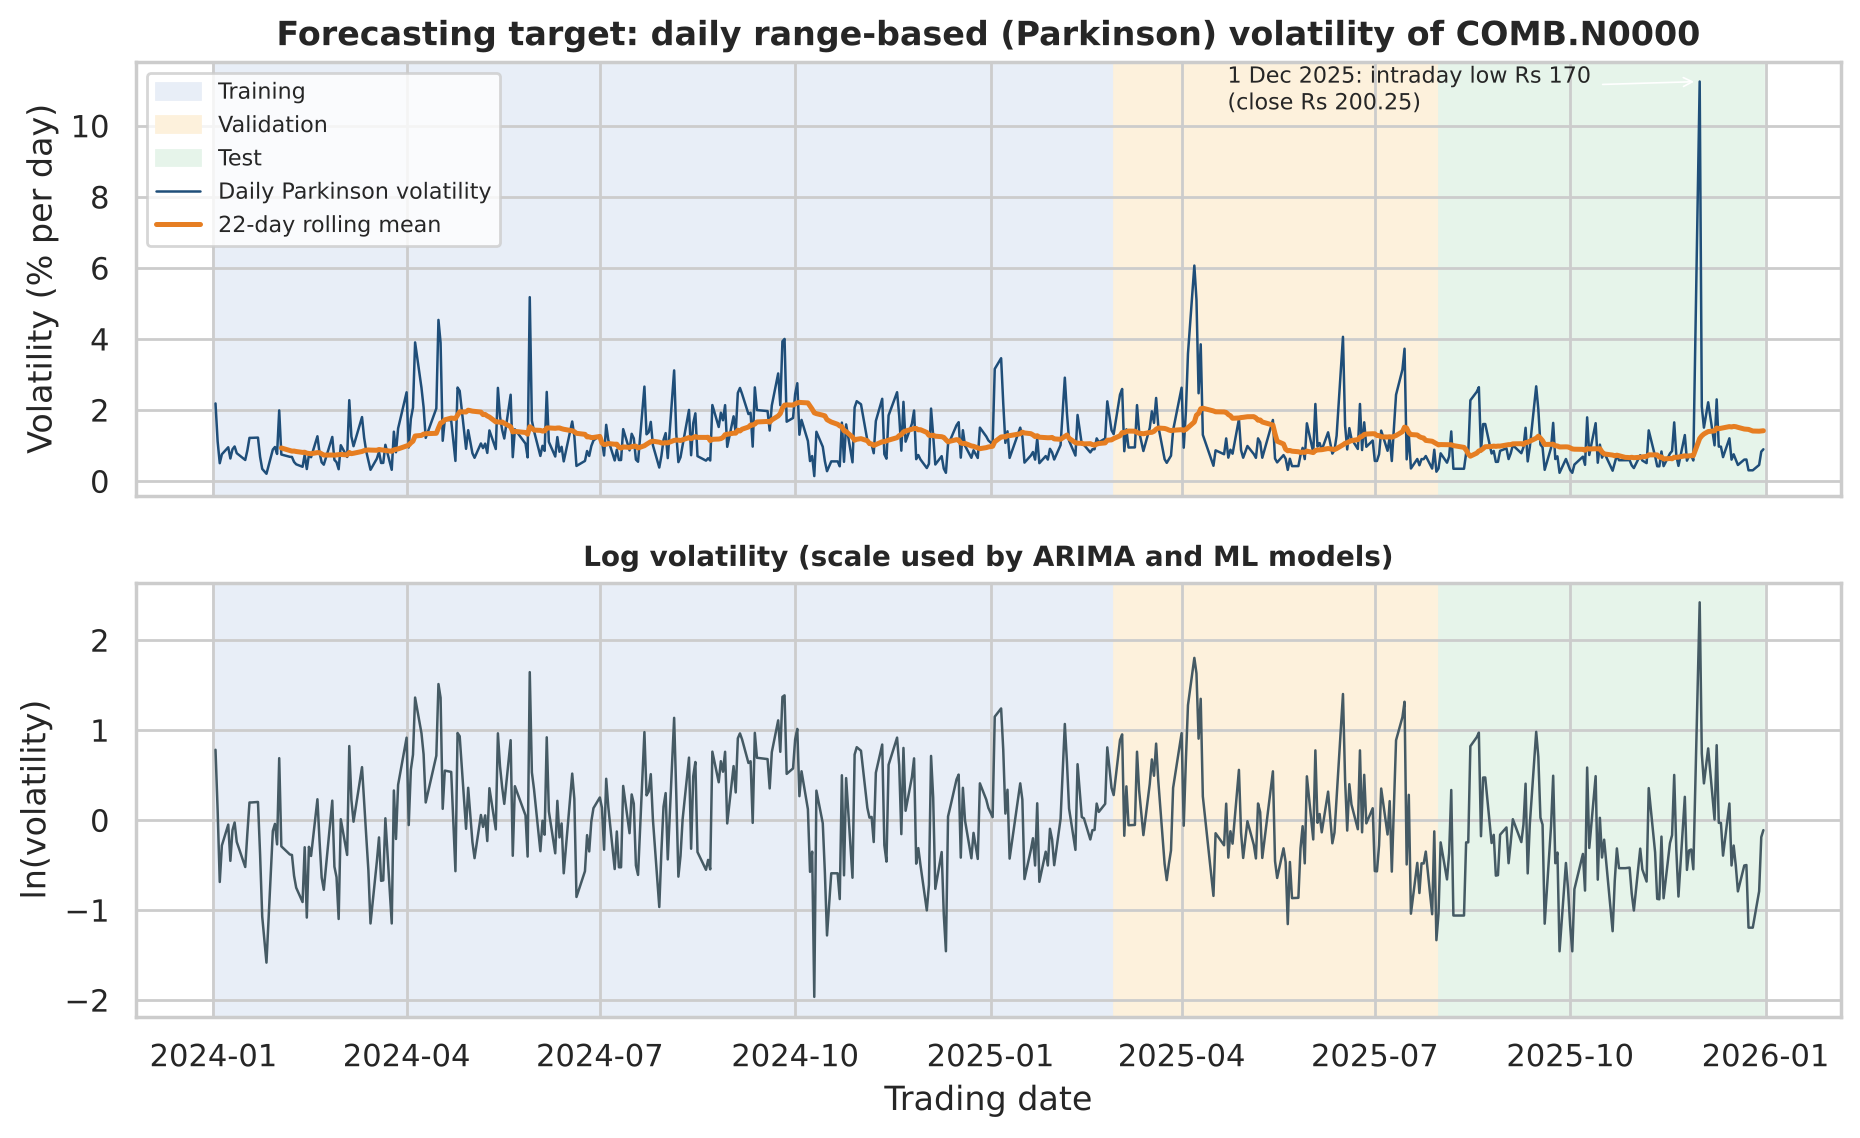

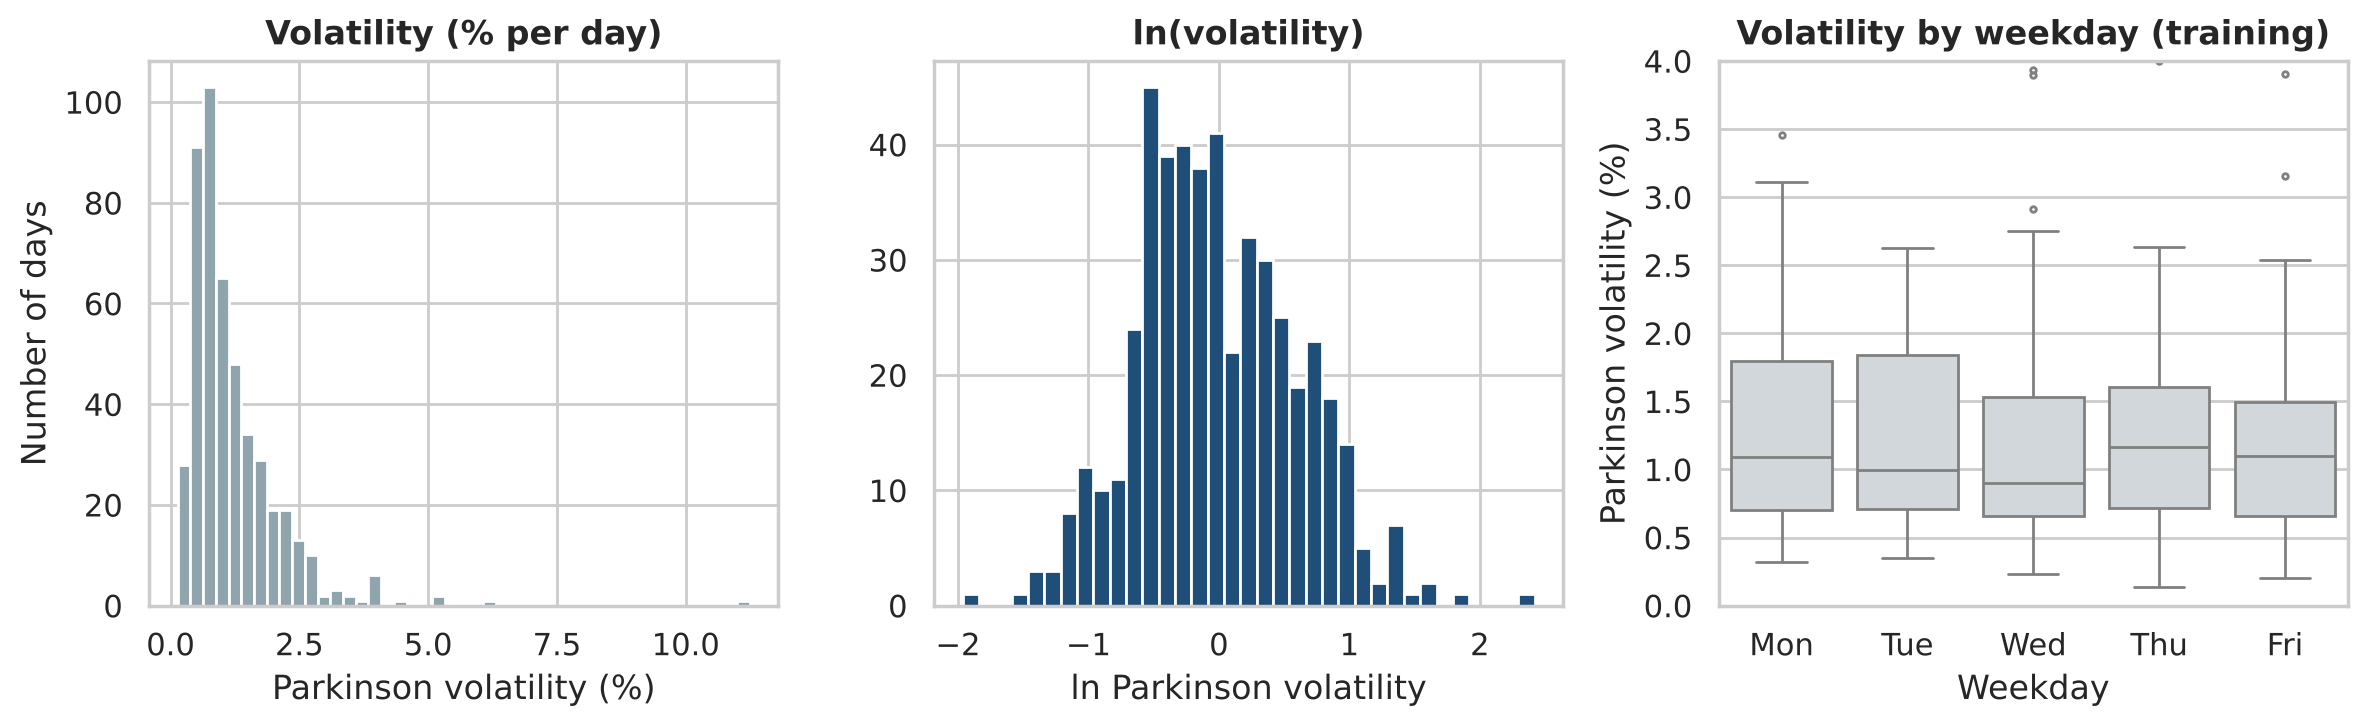

Kruskal-Wallis weekday test (training): (1.2027248590504076, 0.8776497840256365)


In [8]:
show(eda.fig_target(g)); show(eda.fig_target_distribution(g))
print("Kruskal-Wallis weekday test (training):", eda.weekday_test(g))

**Interpretation.** Volatility is strongly right-skewed; its logarithm is close to symmetric, so ARIMA and ML models are fitted to
ln(volatility). No weekday pattern was found (Kruskal–Wallis p ≈ 0.88), so a seasonal model (SARIMA) is not justified.
The extreme value on 1 Dec 2025 (intraday low Rs 170 vs close Rs 200.25, the first trading day after Cyclone Ditwah) is kept, not deleted,
and analysed separately later.

## 4. Statistical tests (training sample only)
Decisions about differencing and model structure use only training data, so test information cannot leak into model design.

,ADF stat,ADF p,KPSS stat,KPSS p,conclusion (5%)
series,,,,,
log close price,-0.1343,0.9459,1.5084,0.0100,non-stationary (both tests agree)
adjusted log return,-13.1148,0.0000,0.1651,0.1000,stationary (both tests agree)
log Parkinson volatility,-6.2231,0.0000,0.2172,0.1000,stationary (both tests agree)


,test,series,statistic,p-value,reject H0 at 5%?
0,Ljung-Box Q(5),adjusted return,24.7665,0.0002,yes
1,Ljung-Box Q(10),adjusted return,30.1089,0.0008,yes
2,Ljung-Box Q(5),squared return,9.1364,0.1037,no
3,Ljung-Box Q(10),squared return,11.0374,0.3546,no
4,Ljung-Box Q(5),log Parkinson vol,102.8893,0.0000,yes
5,Ljung-Box Q(10),log Parkinson vol,130.6317,0.0000,yes
6,ARCH-LM (5 lags),adjusted return,5.4444,0.3641,no
7,Jarque-Bera,adjusted return,202.0033,0.0000,yes


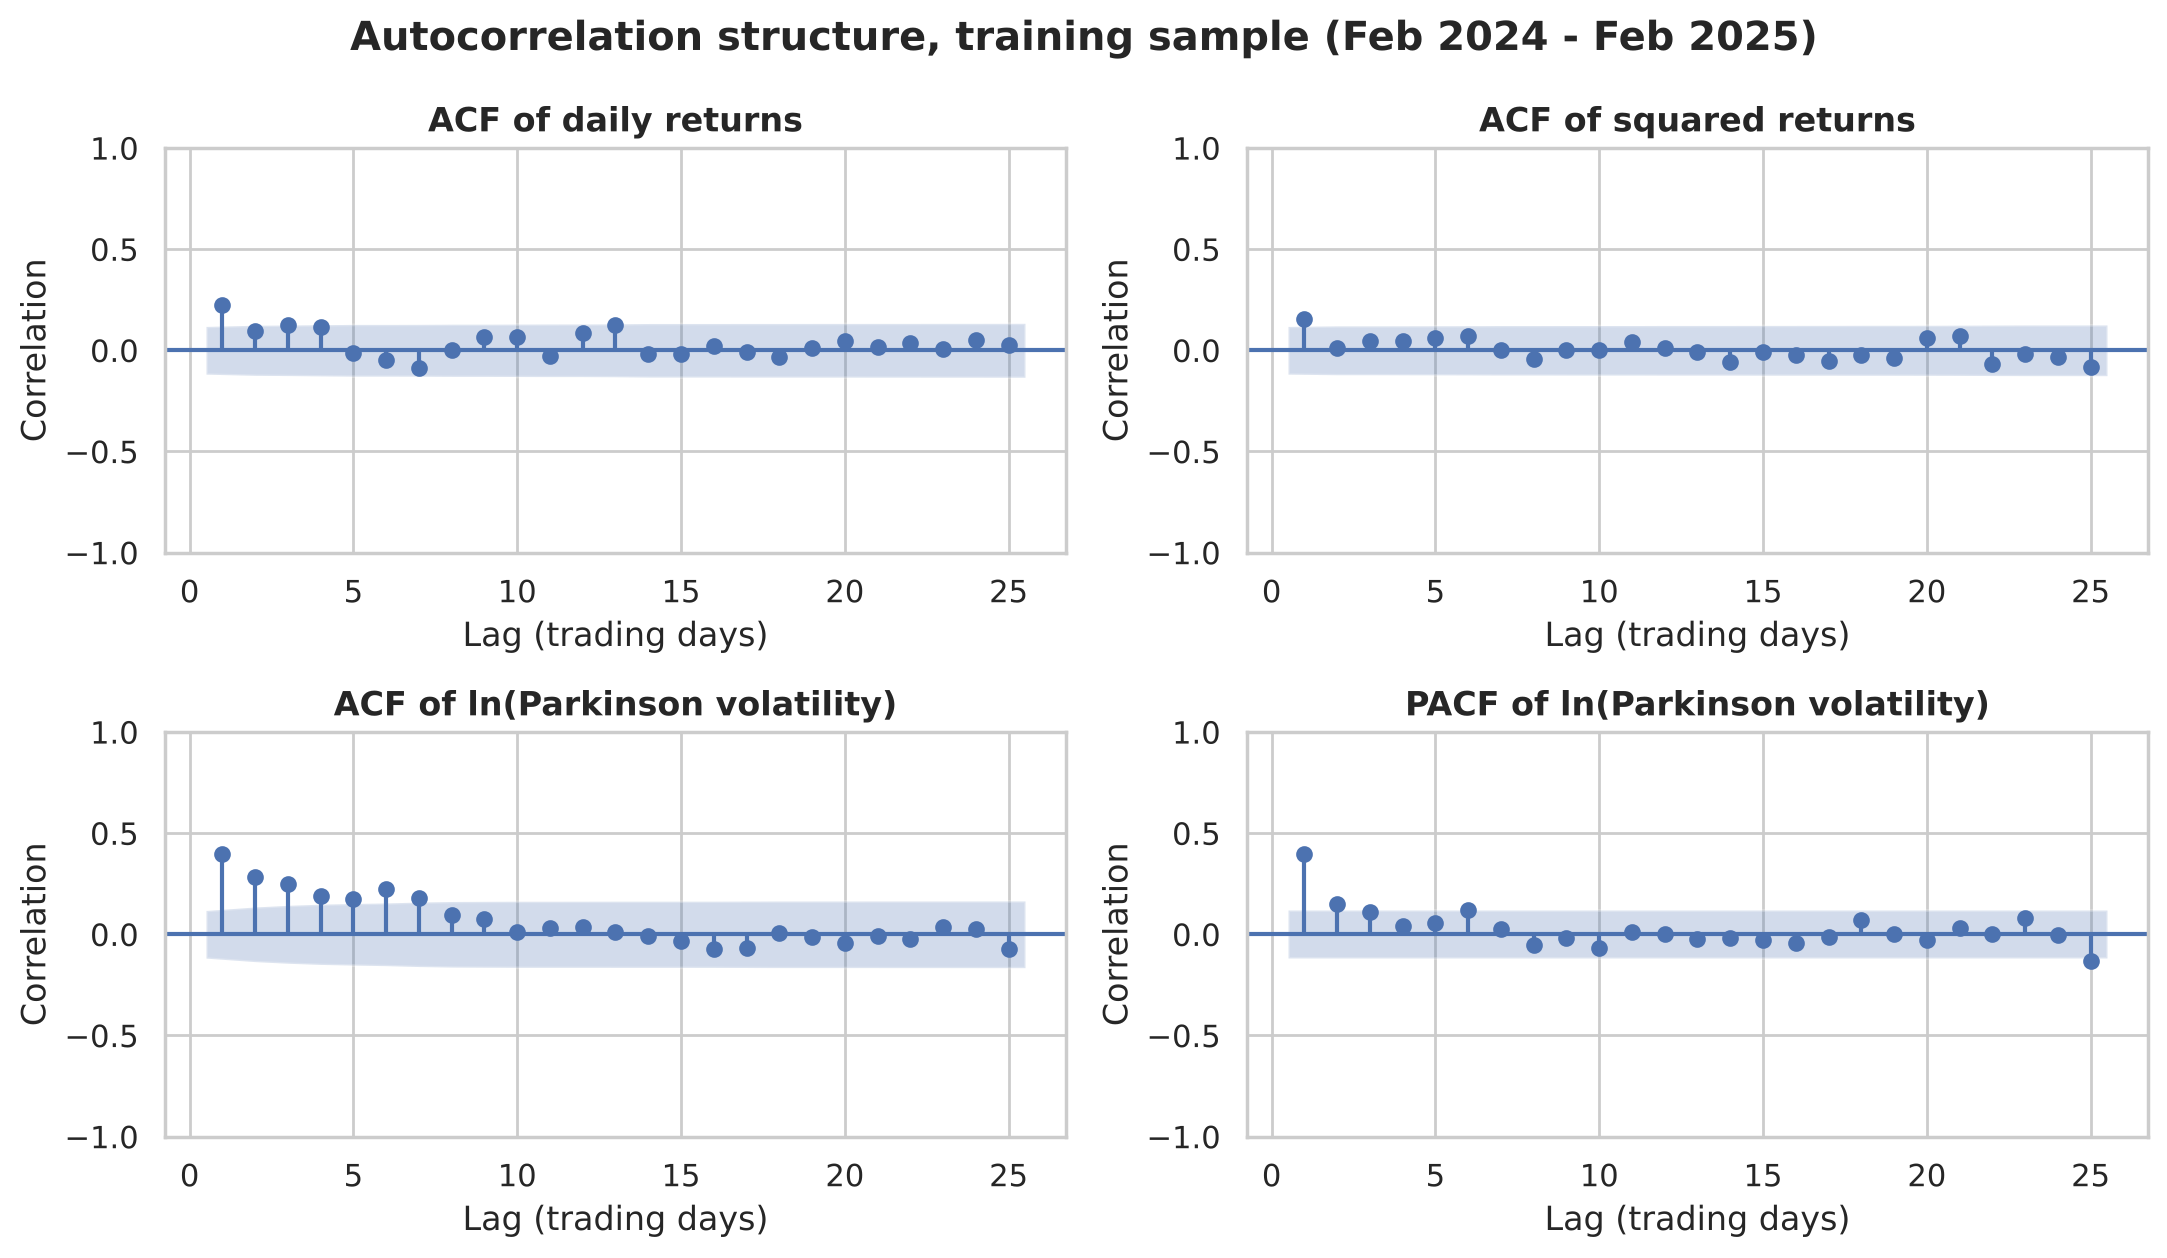

In [9]:
display(eda.stationarity_tests(g)); display(eda.dependence_tests(g)); show(eda.fig_acf(g))

**Interpretation.**
* log price: non-stationary (ADF cannot reject a unit root; KPSS rejects stationarity) → price levels are not modelled.
* returns and log-volatility: stationary → ARIMA with **d = 0** on log-volatility.
* log-volatility has very strong autocorrelation (Ljung–Box p < 0.001) → volatility is forecastable.
* Squared returns show *no* significant autocorrelation and the ARCH-LM test is not significant. Volatility clustering exists
  (see log-vol), but squared daily returns are too noisy to reveal it. This is an early warning that GARCH, which learns only from
  squared returns, may be at a disadvantage.
* Returns themselves are autocorrelated (Ljung–Box p < 0.001) — common in thinly traded frontier markets — but direction forecasting
  is not our objective.

## 5. Features and the chronological split
Each row is a forecast for day t+1 made at the close of day t; every feature is shifted so it only uses data up to day t.

,set,first target date,last target date,observations,share,used for
0,Training,2024-02-07,2025-02-28,254,55.8%,estimating parameters
1,Validation,2025-03-03,2025-07-31,99,21.8%,choosing orders / hyper-parameters
2,Test,2025-08-01,2025-12-31,102,22.4%,"final, untouched comparison"


,feature,description
0,lv_0,log Parkinson volatility on day t (most recent...
1,lv_1,log Parkinson volatility on day t-1
2,lv_2,log Parkinson volatility on day t-2
3,lv_w,log of the 5-day average Parkinson volatility ...
4,lv_m,log of the 22-day average Parkinson volatility...
5,absret_0,absolute adjusted return on day t (size of las...
6,absret_w,average absolute adjusted return over the last...
7,ret_0,signed adjusted return on day t (captures the ...
8,ret_m,cumulative adjusted return over the last 22 da...
9,log_volume_0,log of shares traded on day t (activity / liqu...


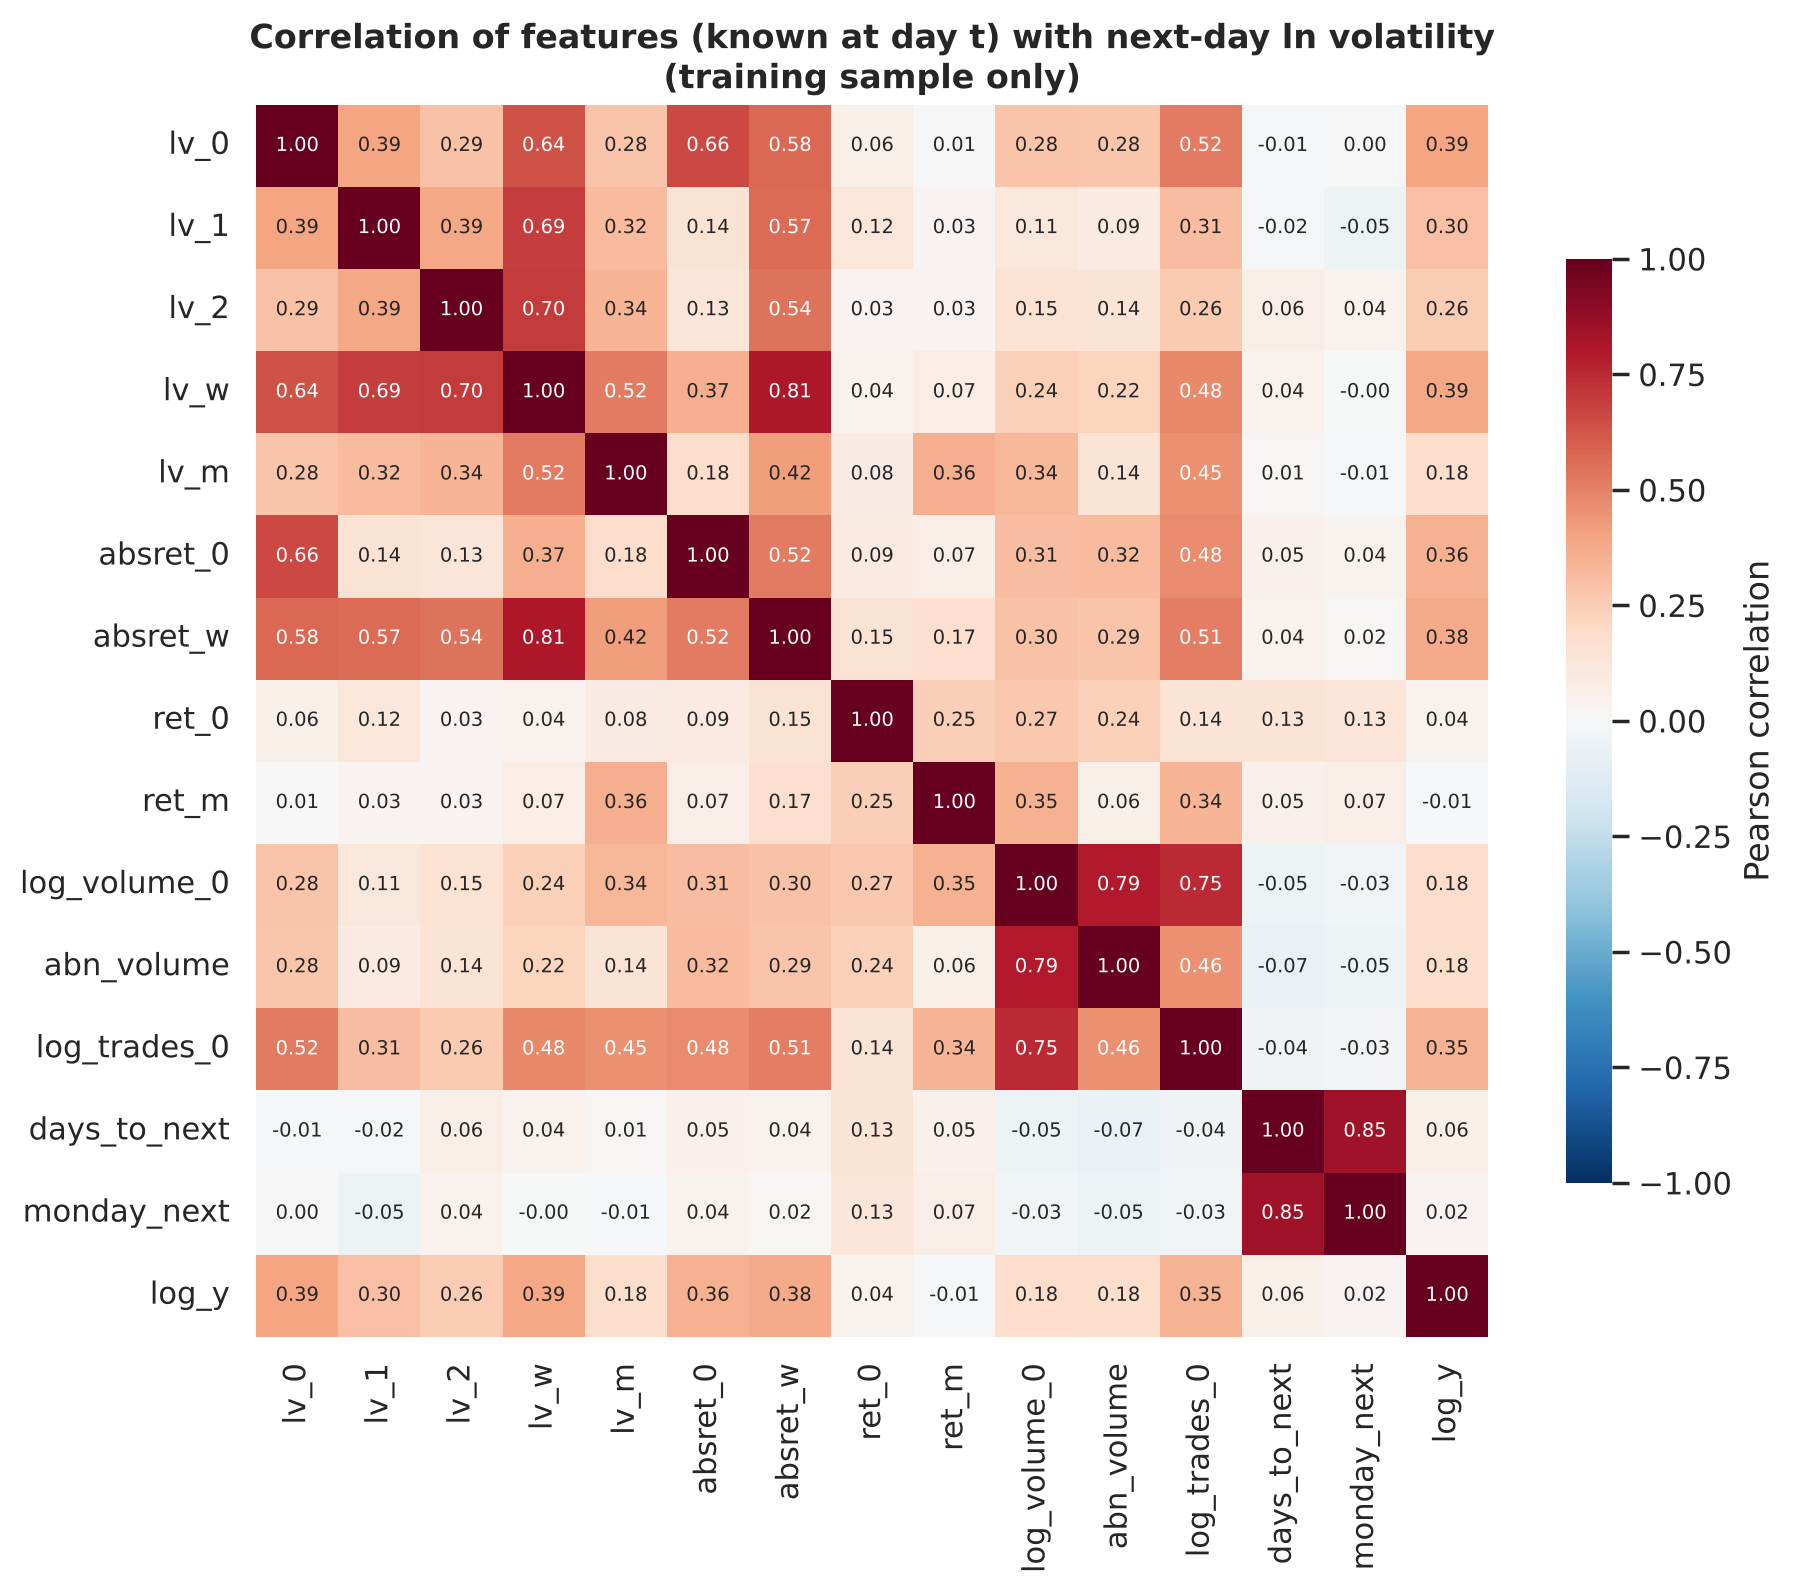

In [10]:
d = fe.build_features(g)
train, val, test = fe.split(d)
display(fe.split_table(train, val, test))
display(pd.DataFrame({"feature": fe.FEATURES, "description": [fe.FEATURE_DESCRIPTIONS[f] for f in fe.FEATURES]}))
show(eda.fig_correlation(train))

## 6. Fit all models
`run_models` performs, in order: ARIMA order by AIC on training data → GARCH variant by validation QLIKE →
ML hyper-parameters by validation QLIKE → re-estimation on training + validation → one forecast per test day with fixed parameters.

In [11]:
res = run_models("N")
pred = res["pred"]
display(res["details"]["arima"]["selection"].head(6))
display(dg.arima_params_table(res))
display(res["details"]["garch"]["selection"])
display(dg.garch_params_table(res))
for k, v in res["details"]["ml"].items():
    print(k, "-> best:", v["best"]); display(v["tuning"].head(5))

[N] ARIMA order by AIC: (1, 0, 1)


[N] GARCH variant by validation QLIKE: GARCH(1,1)-t
[N] Ridge regression best params: {'alpha': np.float64(0.01)}


[N] Random forest best params: {'max_depth': 6, 'min_samples_leaf': 5, 'max_features': np.float64(0.33)}


[N] Gradient boosting best params: {'learning_rate': np.float64(0.05), 'n_estimators': 100, 'max_depth': 2}


,order,AIC,BIC,converged
0,"(1, 0, 1)",447.0741,461.5702,True
1,"(1, 0, 2)",448.1404,466.2605,True
2,"(2, 0, 1)",448.1850,466.3051,True
3,"(2, 0, 2)",450.1114,471.8555,True
4,"(1, 0, 3)",450.1197,471.8638,True
5,"(3, 0, 1)",450.1295,471.8736,True


...

,alpha,val_QLIKE
0,0.0100,0.5870
1,0.1000,0.5871
2,1.0000,0.5878
3,10.0000,0.5940
4,30.0000,0.6039


Random forest -> best: {'max_depth': 6, 'min_samples_leaf': 5, 'max_features': np.float64(0.33)}


,max_depth,min_samples_leaf,max_features,val_QLIKE
0,6.0000,5,0.3300,0.6766
1,NaN,5,0.3300,0.6786
2,3.0000,15,1.0000,0.6788
3,3.0000,5,1.0000,0.6805
4,6.0000,15,1.0000,0.6810


Gradient boosting -> best: {'learning_rate': np.float64(0.05), 'n_estimators': 100, 'max_depth': 2}


,learning_rate,n_estimators,max_depth,val_QLIKE
0,0.0500,100,2,0.6627
1,0.0200,300,2,0.7020
2,0.0200,100,2,0.7057
3,0.0500,100,3,0.7193
4,0.0500,300,2,0.7266


**Interpretation.** ARIMA(1,0,1) on log-volatility has AR = 0.77 and MA = −0.44: volatility shocks persist but partly fade
within days. The GARCH(1,1)-t parameters are imprecise (β only marginally significant, heavy tails ν ≈ 3.8), consistent with the weak
ARCH evidence in squared returns. Ridge selected the smallest penalty (α = 0.01), i.e. effectively ordinary least squares;
the trees chose shallow-to-moderate depth.

## 7. Results: validation and test comparison
Metrics: **QLIKE** (primary; robust to noisy volatility proxies, penalises under-predicting risk), RMSE and MAE in percentage points
of daily volatility, Mincer–Zarnowitz R².

In [12]:
comp = dg.comparison_table(res)
display(comp[["approach","train QLIKE","val QLIKE","test QLIKE","val RMSE","test RMSE","test MAE","test MZ R2","val rank (QLIKE)","test rank (QLIKE)"]])
display(dg.improvement_table(comp))

,approach,train QLIKE,val QLIKE,test QLIKE,val RMSE,test RMSE,test MAE,test MZ R2,val rank (QLIKE),test rank (QLIKE)
model,,,,,,,,,,
Naive (sigma_t),Baseline,1.8607,0.9888,4.5939,0.9592,1.5116,0.6155,0.0230,6,7
Historical mean (22-day),Baseline,0.7712,1.0464,3.1400,1.0322,1.2063,0.5659,0.0036,7,6
"ARIMA(1, 0, 1) on ln-vol",Traditional,0.6256,0.6589,1.9371,0.8788,1.1465,0.5204,0.0355,2,4
"GARCH(1,1)-t",Traditional,0.6323,0.8163,1.6857,1.0499,1.1493,0.5689,0.0430,5,2
Ridge regression,Machine learning,0.6183,0.5870,1.6584,0.8685,1.1516,0.5659,0.0535,1,1
Random forest,Machine learning,0.3607,0.6766,2.1686,0.8518,1.1515,0.5081,0.0306,4,5
Gradient boosting,Machine learning,0.3343,0.6627,1.8926,0.8357,1.1525,0.5146,0.0342,3,3


,QLIKE improvement vs 22-day mean (%),RMSE improvement vs 22-day mean (%),QLIKE improvement vs naive (%)
model,,,
Naive (sigma_t),-46.3044,-25.3063,0.0000
Historical mean (22-day),0.0000,0.0000,31.6494
"ARIMA(1, 0, 1) on ln-vol",38.3090,4.9616,57.8338
"GARCH(1,1)-t",46.3139,4.7274,63.3052
Ridge regression,47.1837,4.5328,63.8997
Random forest,30.9361,4.5465,52.7944
Gradient boosting,39.7265,4.4566,58.8027


In [13]:
print("Diebold-Mariano vs 22-day historical mean (test):"); display(dg.dm_table(res, "Historical mean (22-day)"))
print("Diebold-Mariano vs Ridge (best on validation):"); display(dg.dm_table(res, comp["val QLIKE"].idxmin()))

Diebold-Mariano vs 22-day historical mean (test):


,DM stat (QLIKE),p (QLIKE),DM stat (squared error),p (squared error)
model,,,,
Naive (sigma_t),1.1377,0.2579,1.0156,0.3122
"ARIMA(1, 0, 1) on ln-vol",-1.2889,0.2004,-2.2973,0.0237
"GARCH(1,1)-t",-1.1844,0.2391,-1.5688,0.1198
Ridge regression,-1.2124,0.2282,-1.5089,0.1345
Random forest,-1.3762,0.1718,-2.0679,0.0412
Gradient boosting,-1.2666,0.2082,-1.7162,0.0892


Diebold-Mariano vs Ridge (best on validation):


,DM stat (QLIKE),p (QLIKE),DM stat (squared error),p (squared error)
model,,,,
Naive (sigma_t),1.1822,0.2399,1.1673,0.2458
Historical mean (22-day),1.2124,0.2282,1.5089,0.1345
"ARIMA(1, 0, 1) on ln-vol",0.9561,0.3413,-0.3502,0.7269
"GARCH(1,1)-t",1.0510,0.2958,-0.1852,0.8535
Random forest,0.9785,0.3302,-0.0093,0.9926
Gradient boosting,0.9722,0.3333,0.0632,0.9498


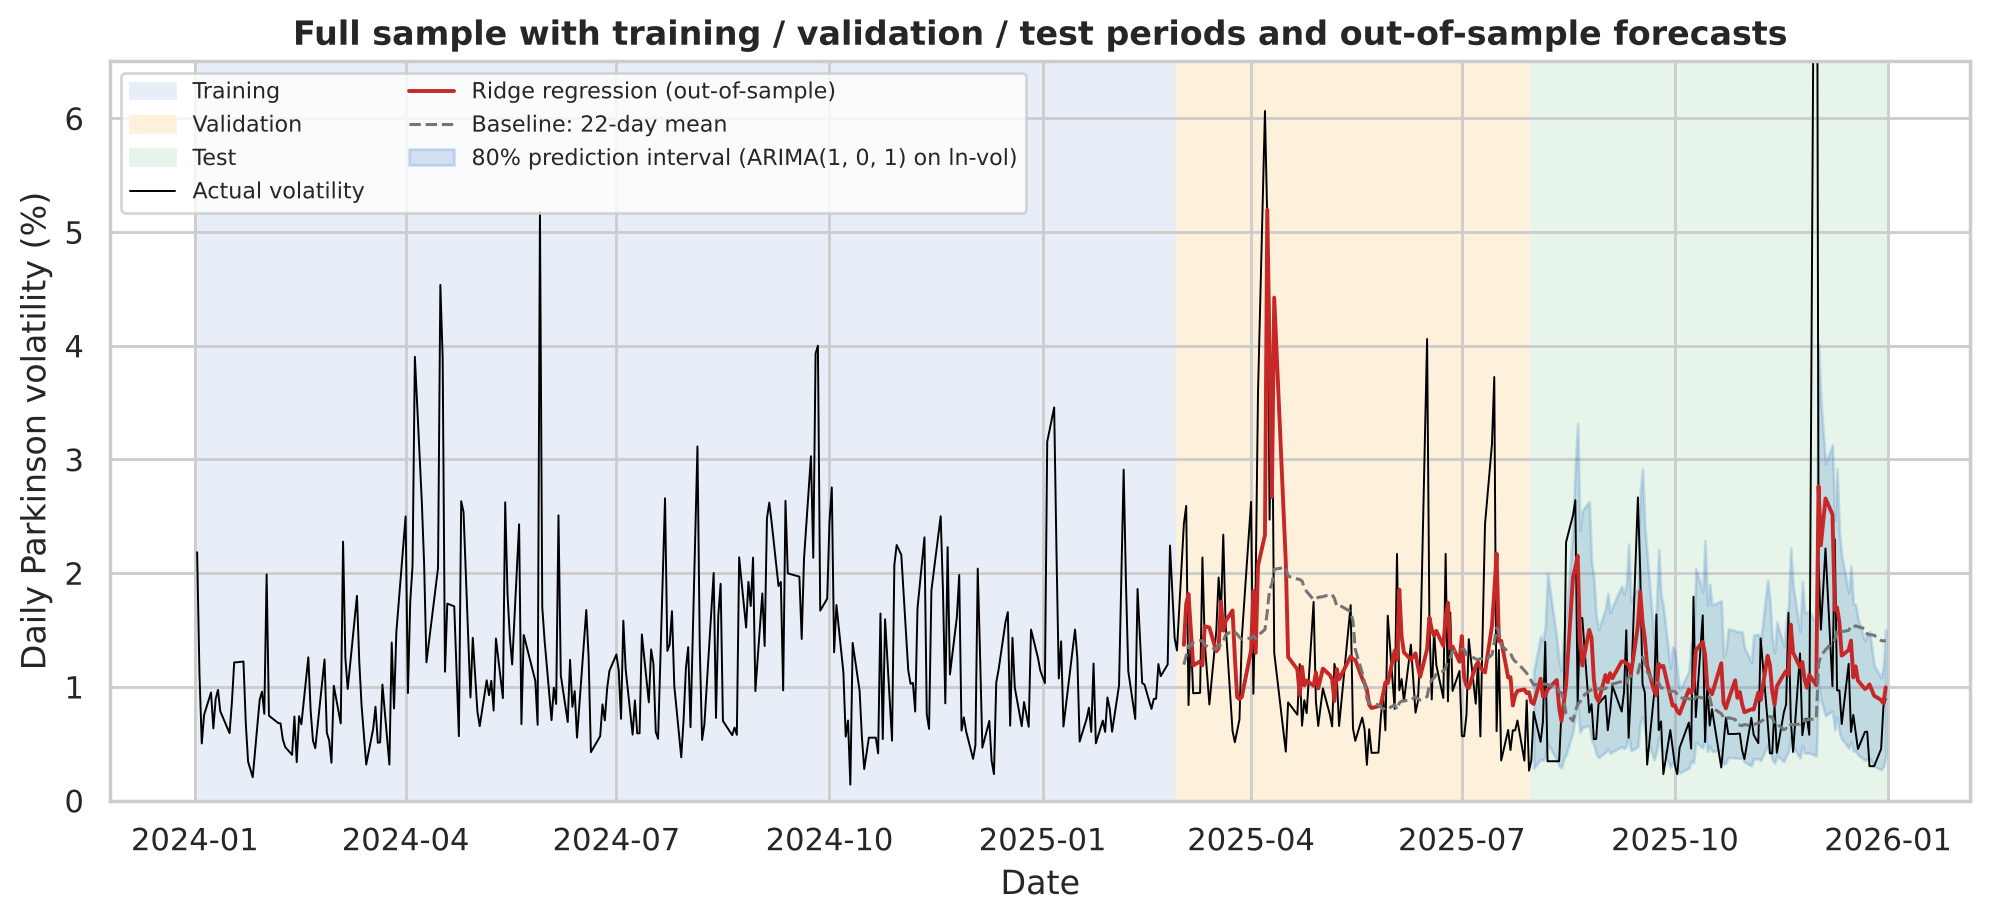

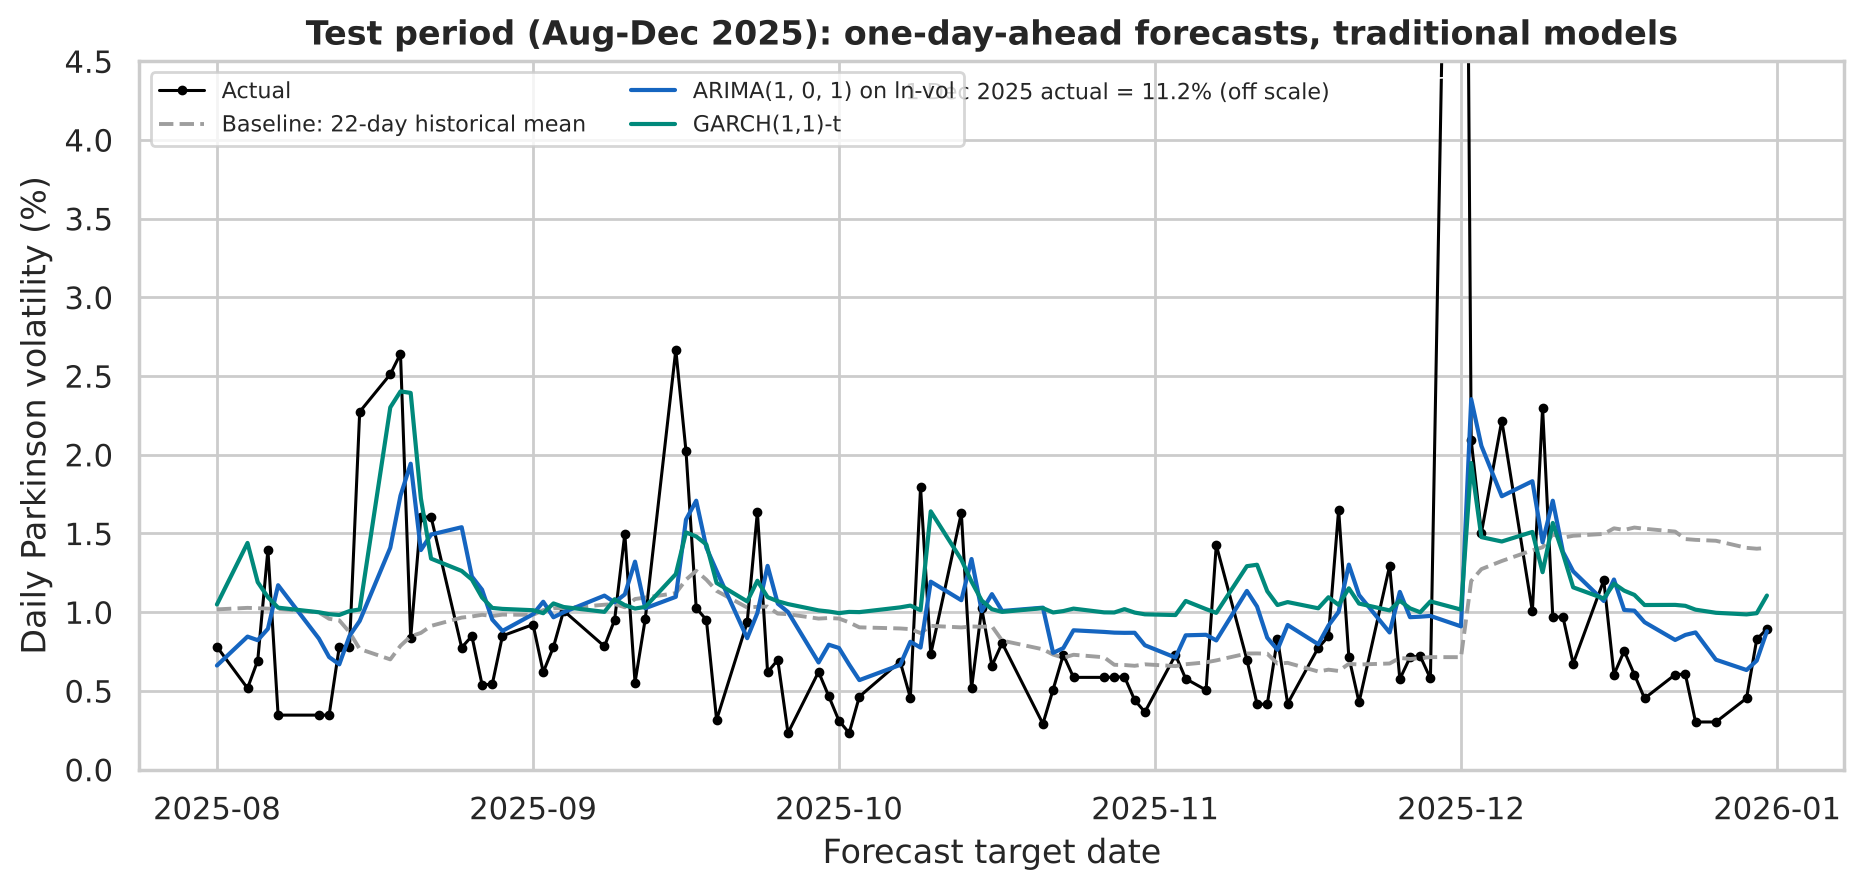

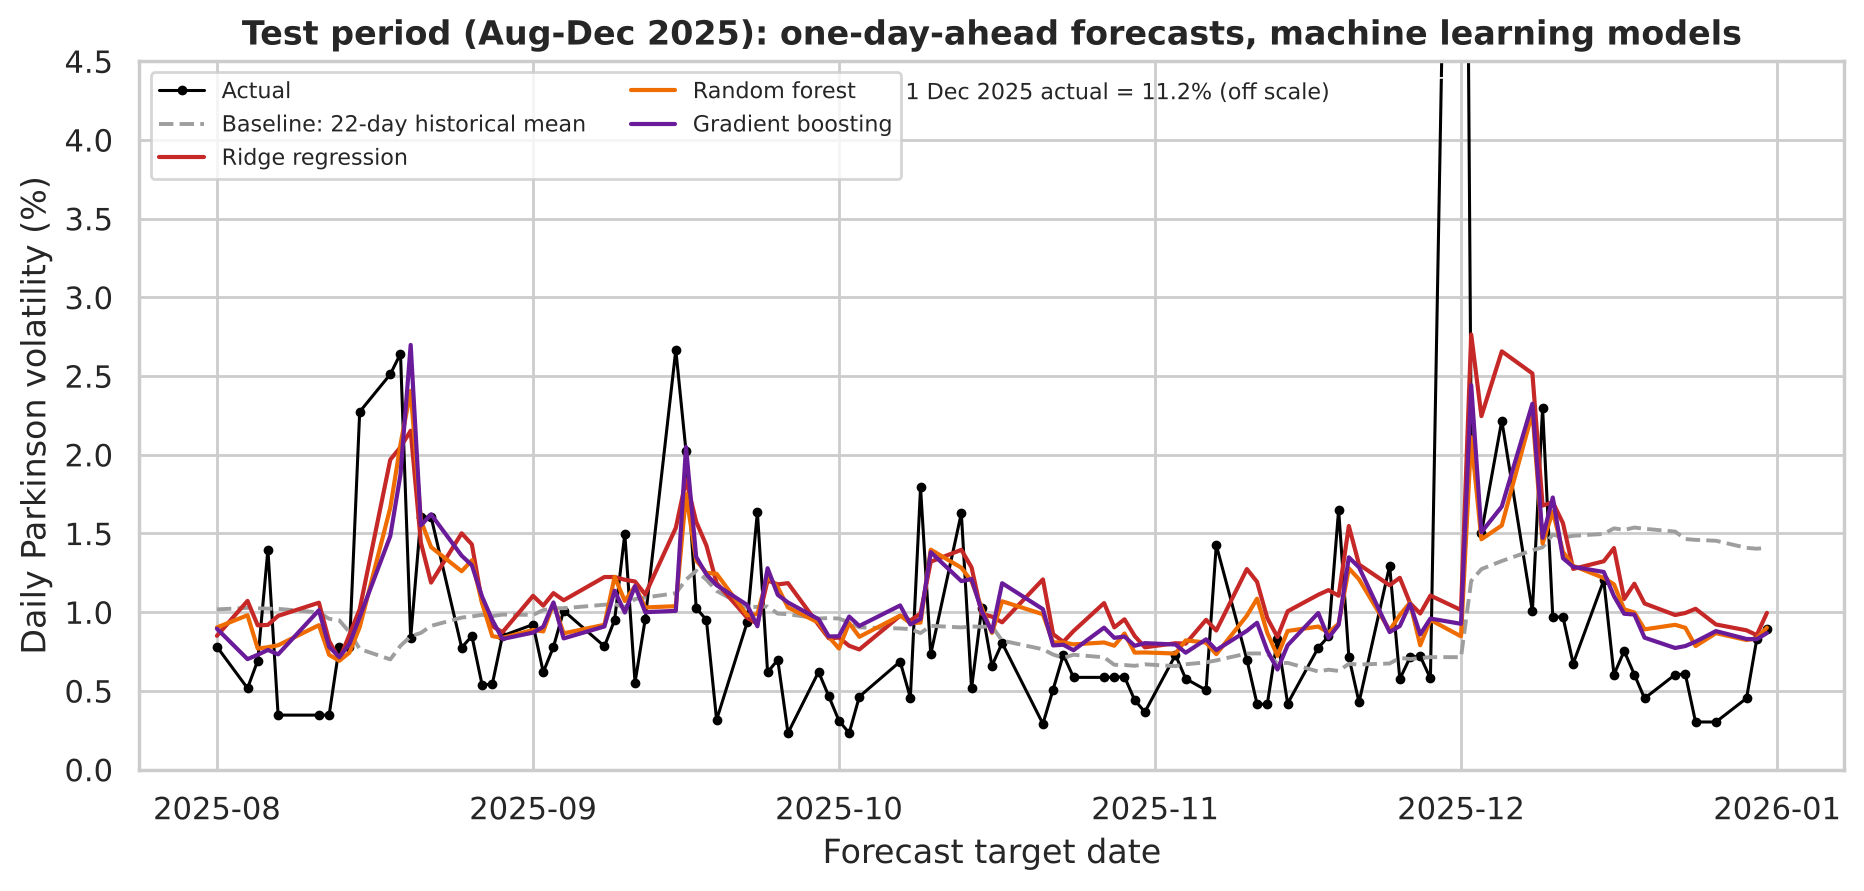

In [14]:
show(dg.fig_full_forecast(res, comp["val QLIKE"].idxmin()))
show(dg.fig_forecasts_test(res, "Traditional", "15a")); show(dg.fig_forecasts_test(res, "Machine learning", "15b"))

## 8. Diagnostics

,model,residual,lag,LB stat,p-value,autocorrelation left? (5%)
0,"ARIMA(1, 0, 1) on ln-vol",one-step ln-vol error,5,0.3762,0.9960,no
1,"ARIMA(1, 0, 1) on ln-vol",one-step ln-vol error,10,5.6561,0.8433,no
2,"ARIMA(1, 0, 1) on ln-vol",one-step ln-vol error,20,9.8304,0.9711,no
3,"GARCH(1,1)-t",standardised,5,23.9769,0.0002,yes
4,"GARCH(1,1)-t",standardised,10,29.6038,0.0010,yes
5,"GARCH(1,1)-t",squared standardised,5,0.5641,0.9896,no
6,"GARCH(1,1)-t",squared standardised,10,1.7706,0.9978,no


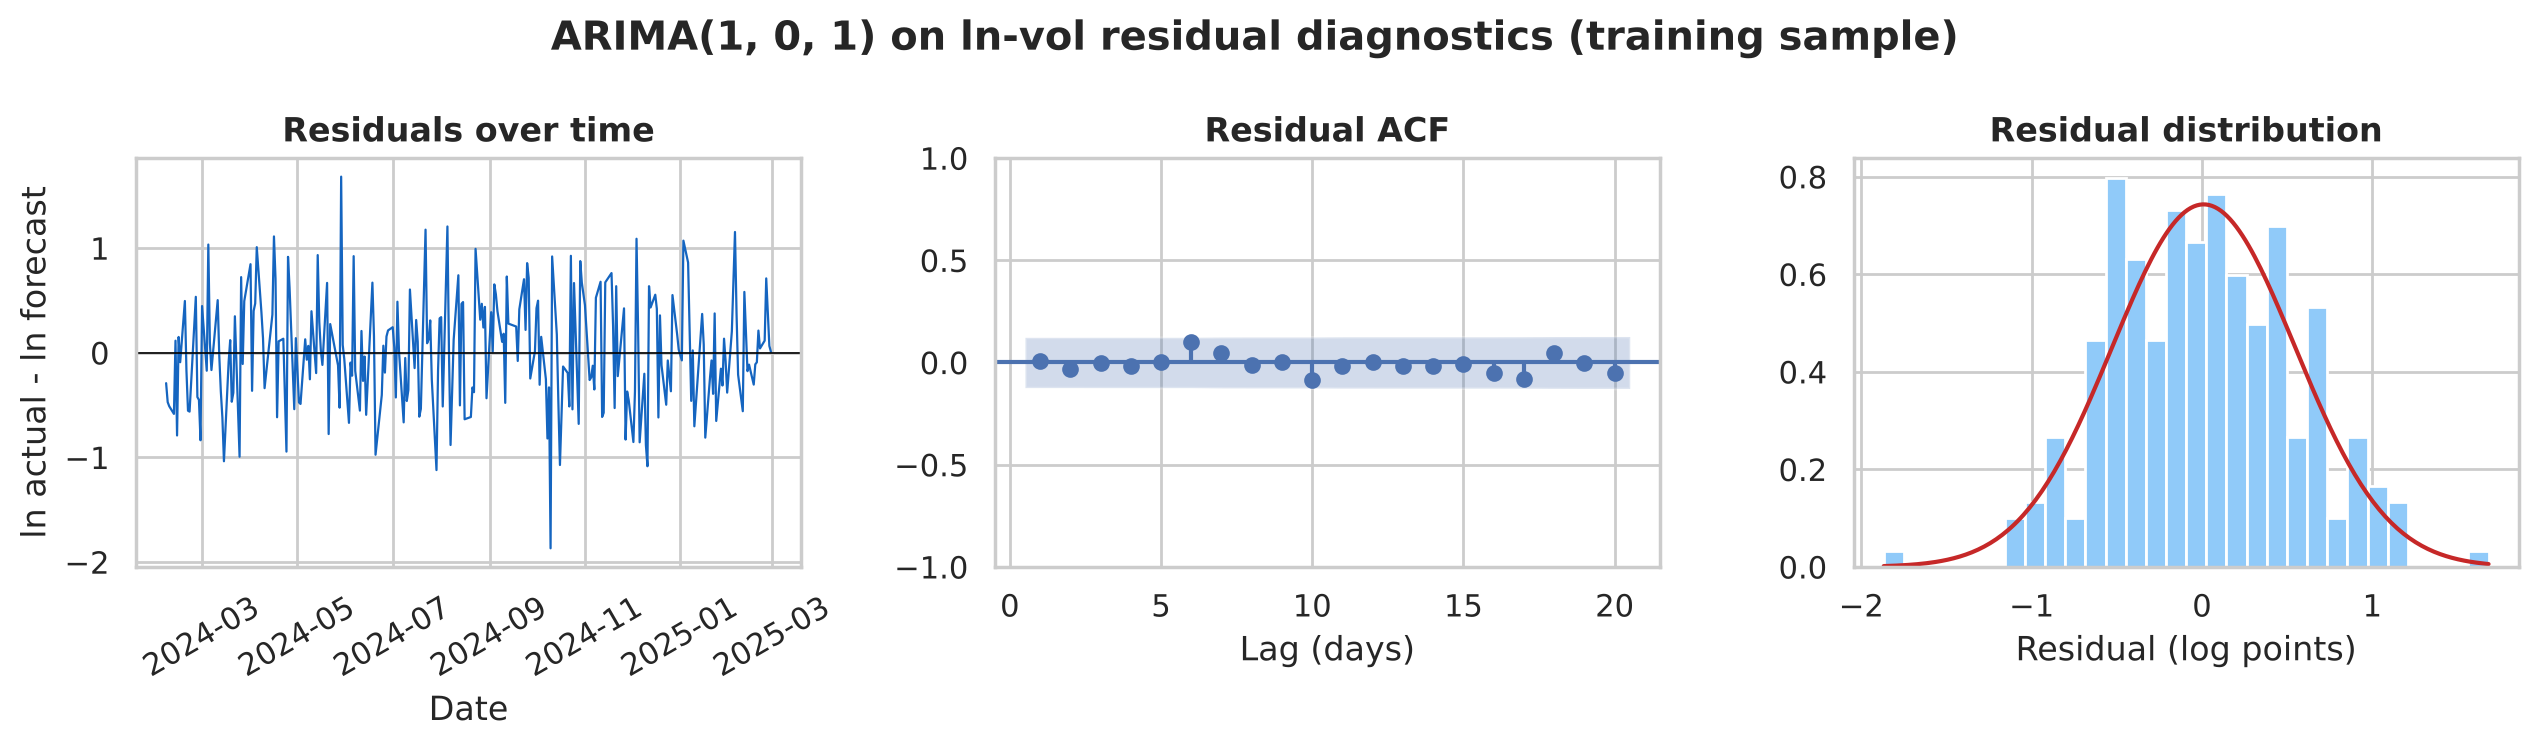

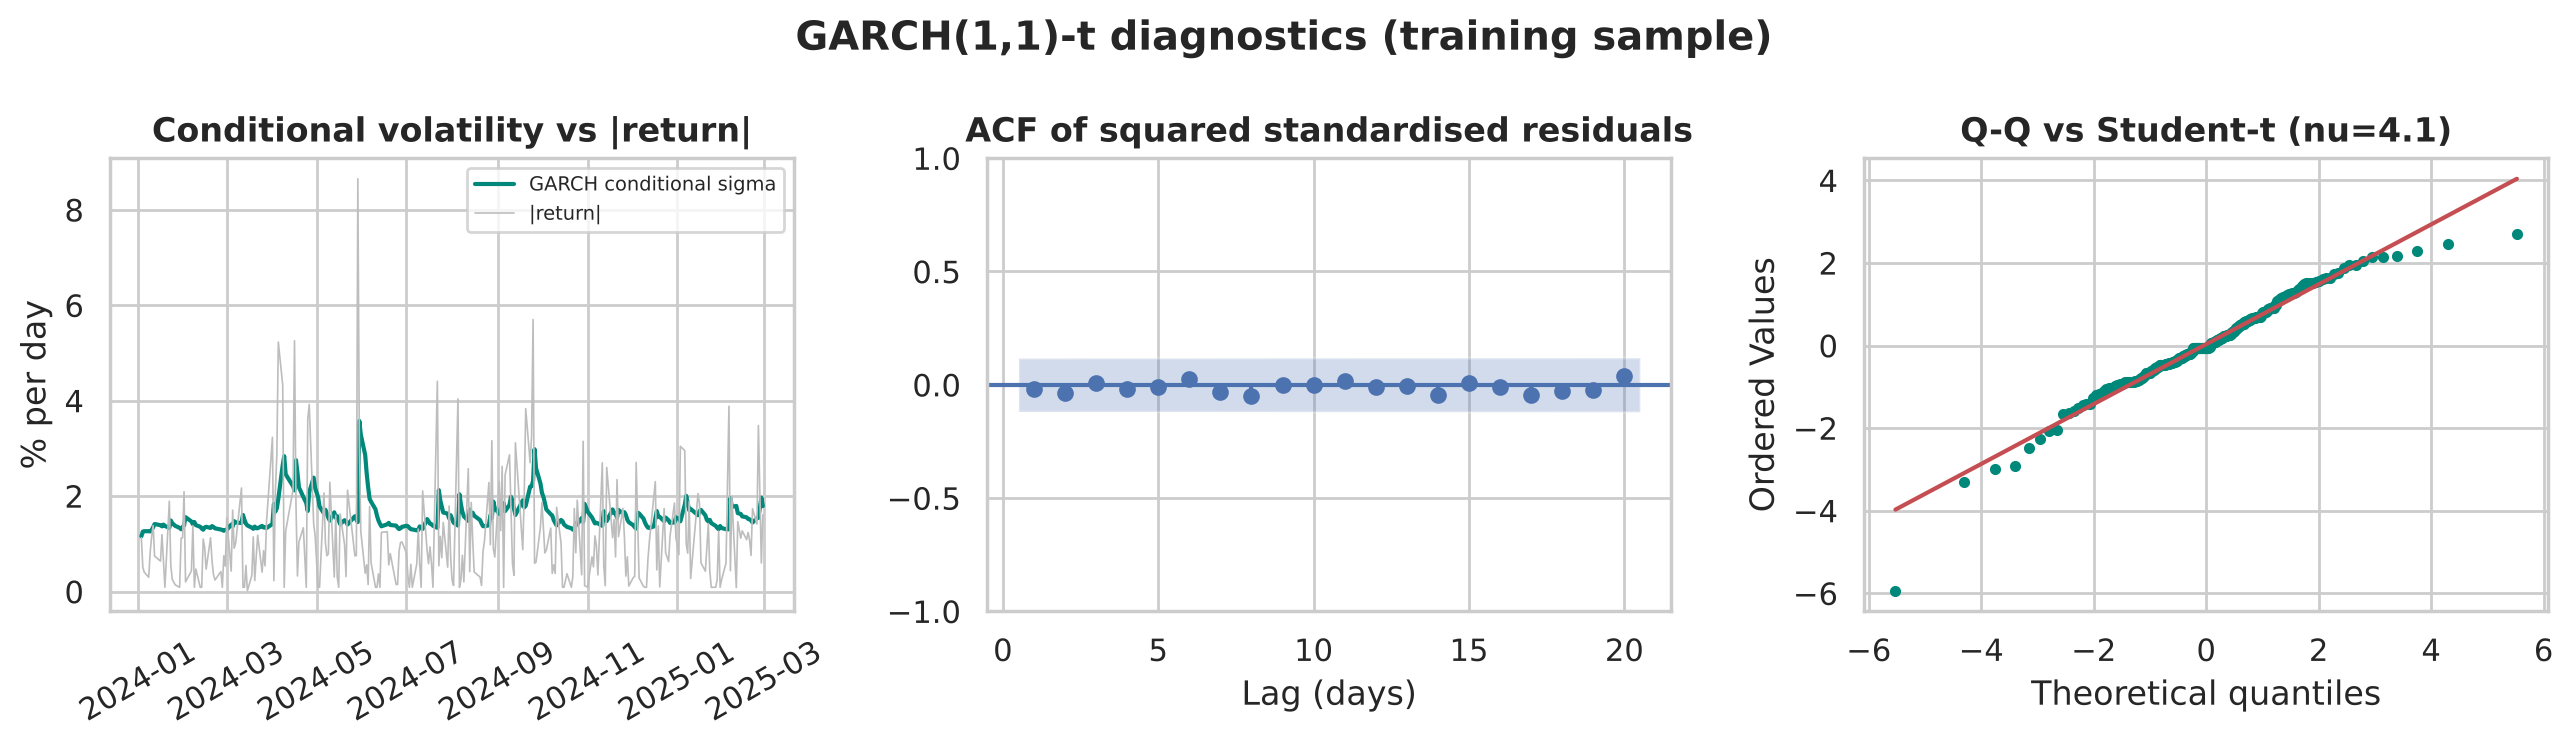

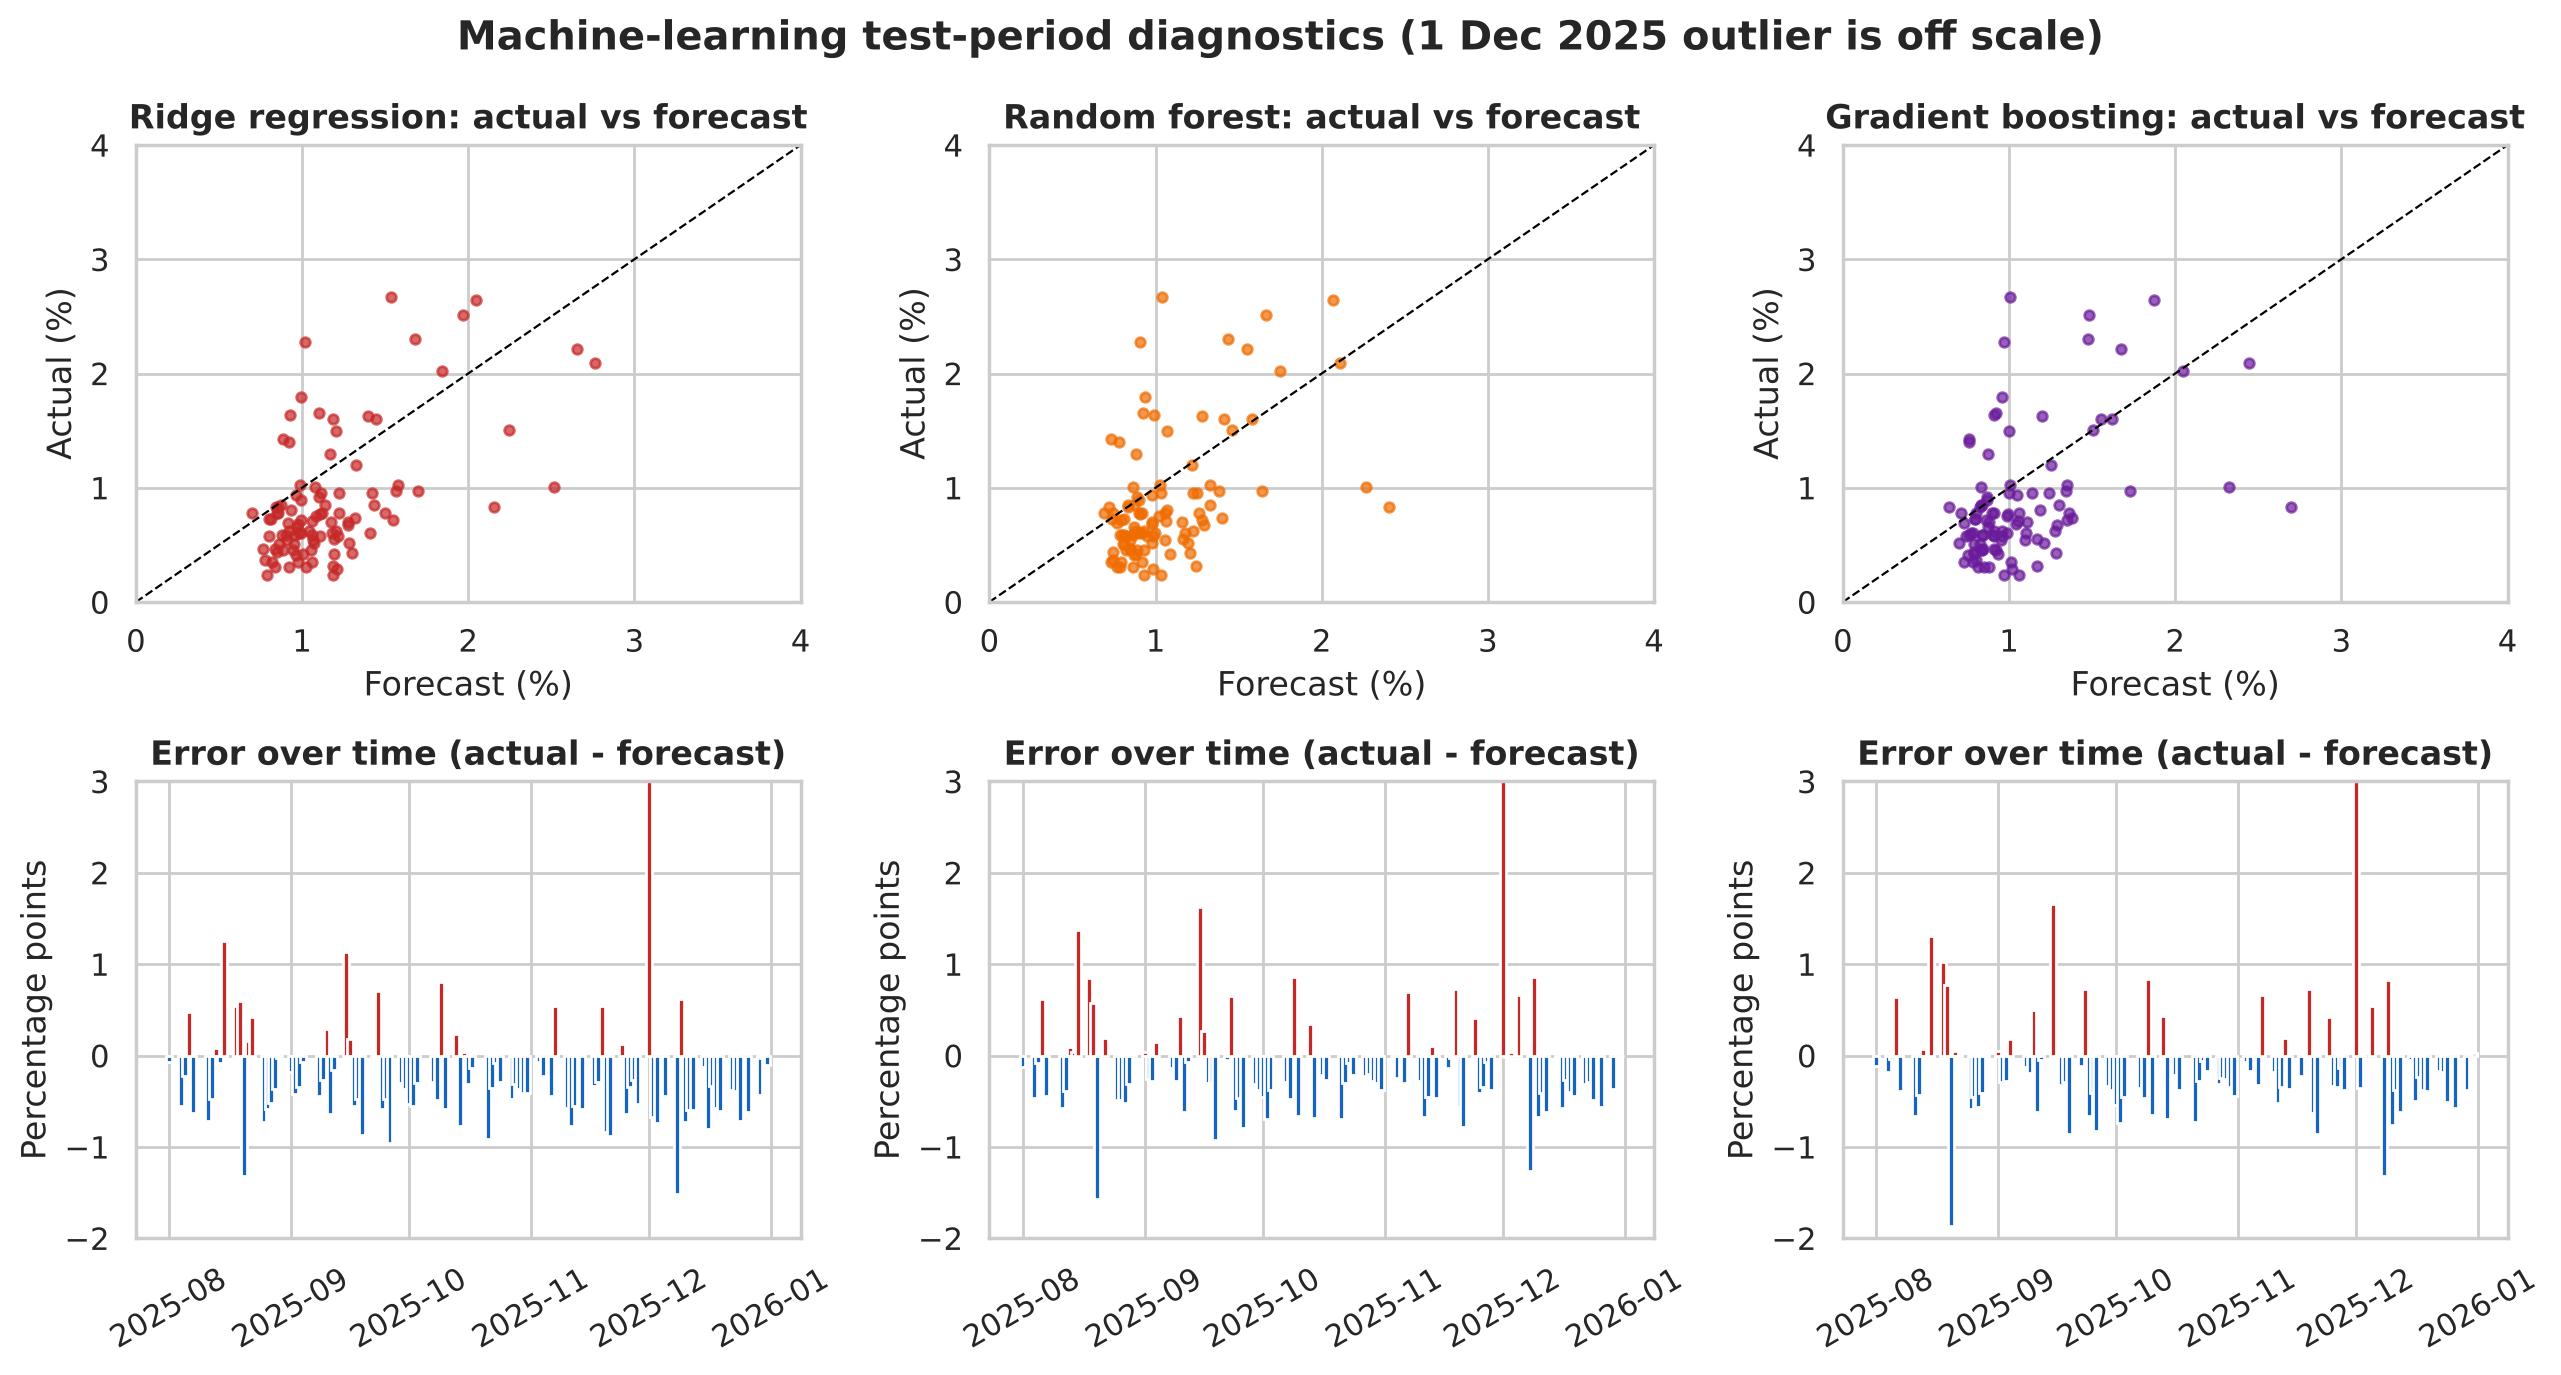

In [15]:
display(dg.residual_tests(res))
show(dg.fig_arima_residuals(res)); show(dg.fig_garch_diagnostics(res)); show(dg.fig_ml_diagnostics(res))

## 9. Additional investigation: volatility regimes, stability and shocks
Regime of each forecast day = high if the trailing 22-day mean volatility (known at the forecast origin) exceeds its training median.

Regime threshold: 1.228% daily volatility


regime,High-volatility,Low-volatility
model,,
"ARIMA(1, 0, 1) on ln-vol",0.6099,1.8293
"GARCH(1,1)-t",0.7532,1.6347
Gradient boosting,0.5593,1.8308
Historical mean (22-day),0.9692,2.9610
Naive (sigma_t),0.8512,4.2893
Random forest,0.5941,2.0616
Ridge regression,0.5653,1.5535


regime,High-volatility,Low-volatility
model,,
"ARIMA(1, 0, 1) on ln-vol",0.6099,0.5590
"GARCH(1,1)-t",0.7532,0.6264
Gradient boosting,0.5593,0.6067
Historical mean (22-day),0.9692,0.8703
Naive (sigma_t),0.8512,1.0785
Random forest,0.5941,0.5869
Ridge regression,0.5653,0.5396


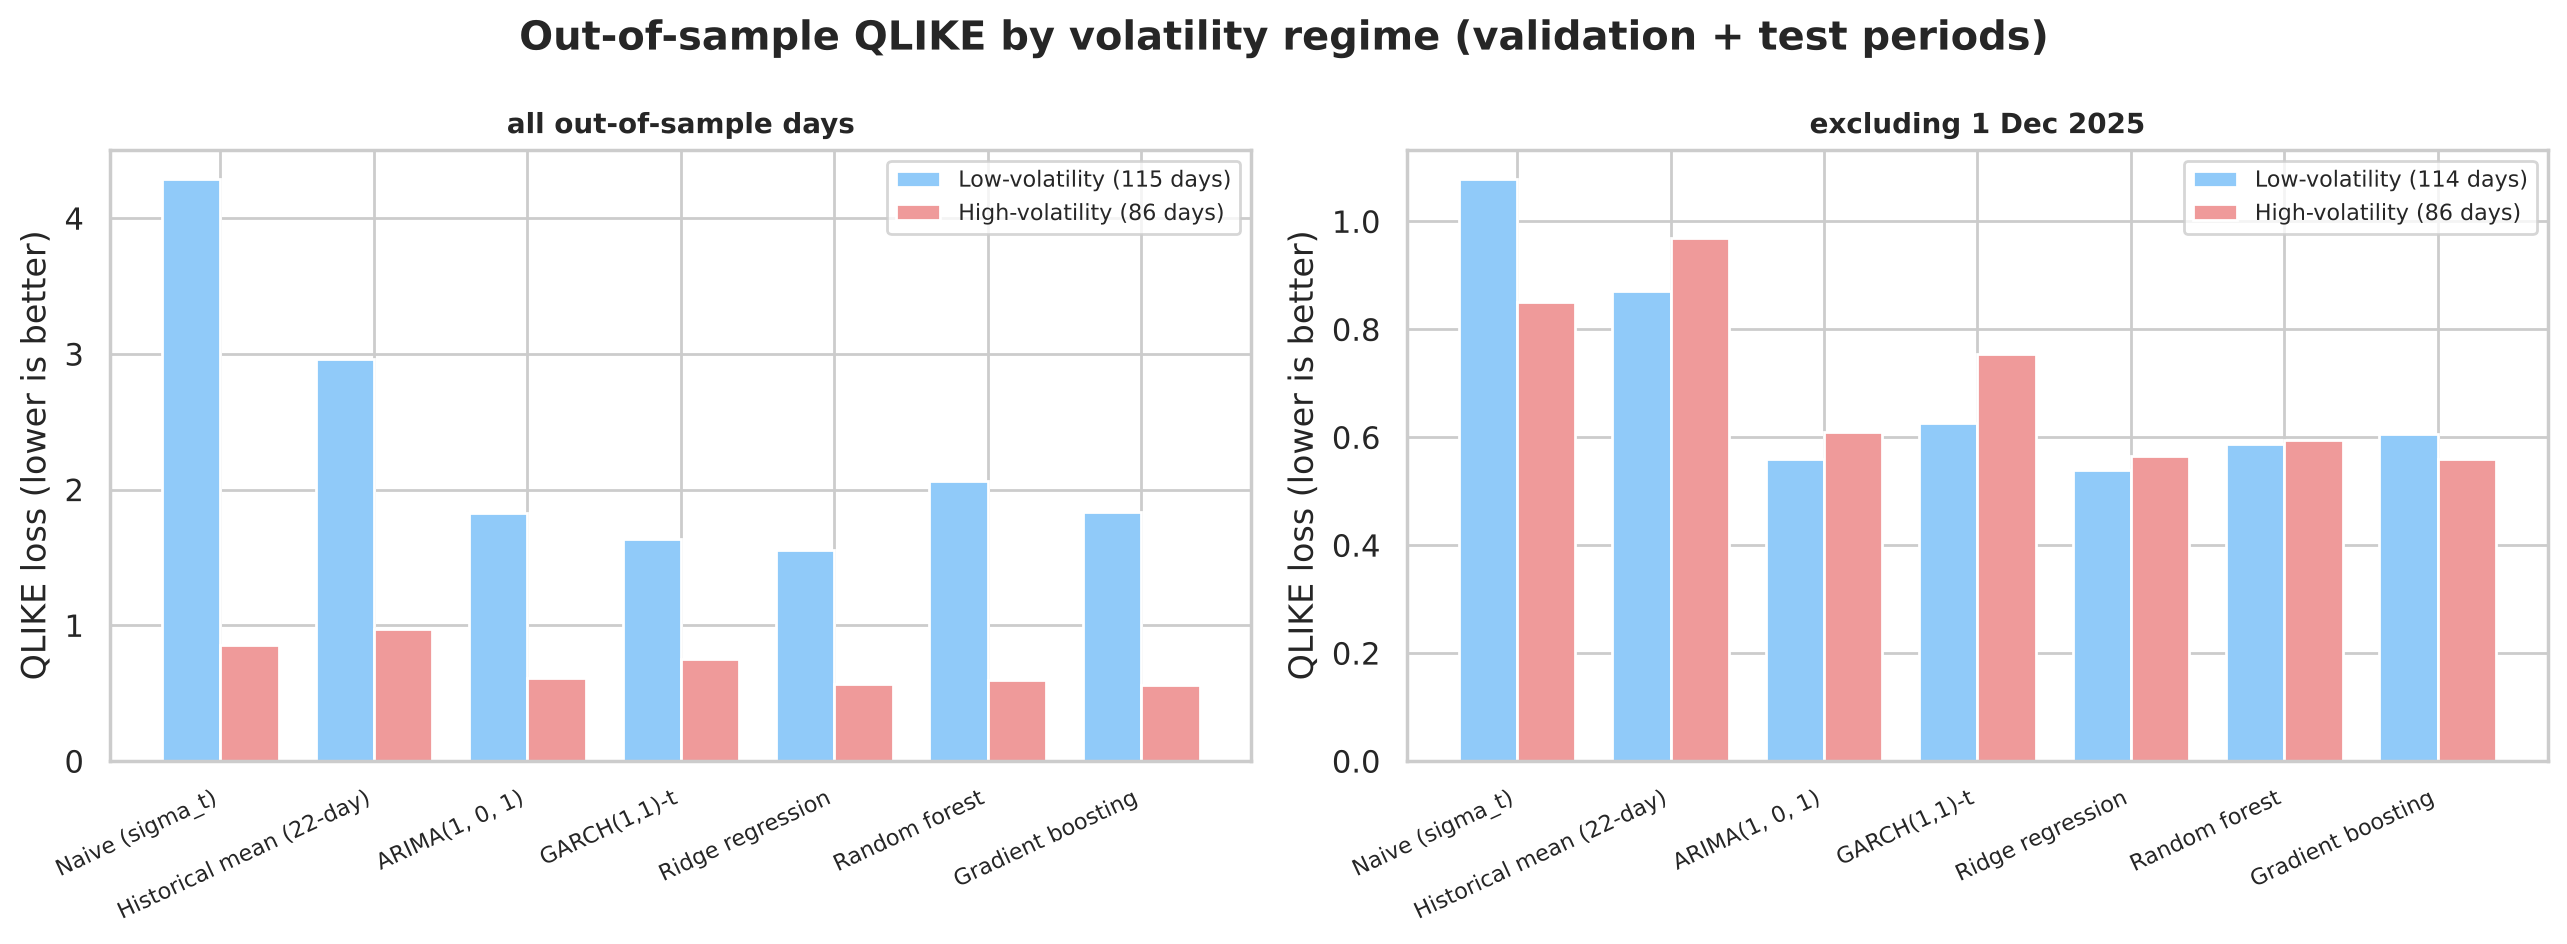

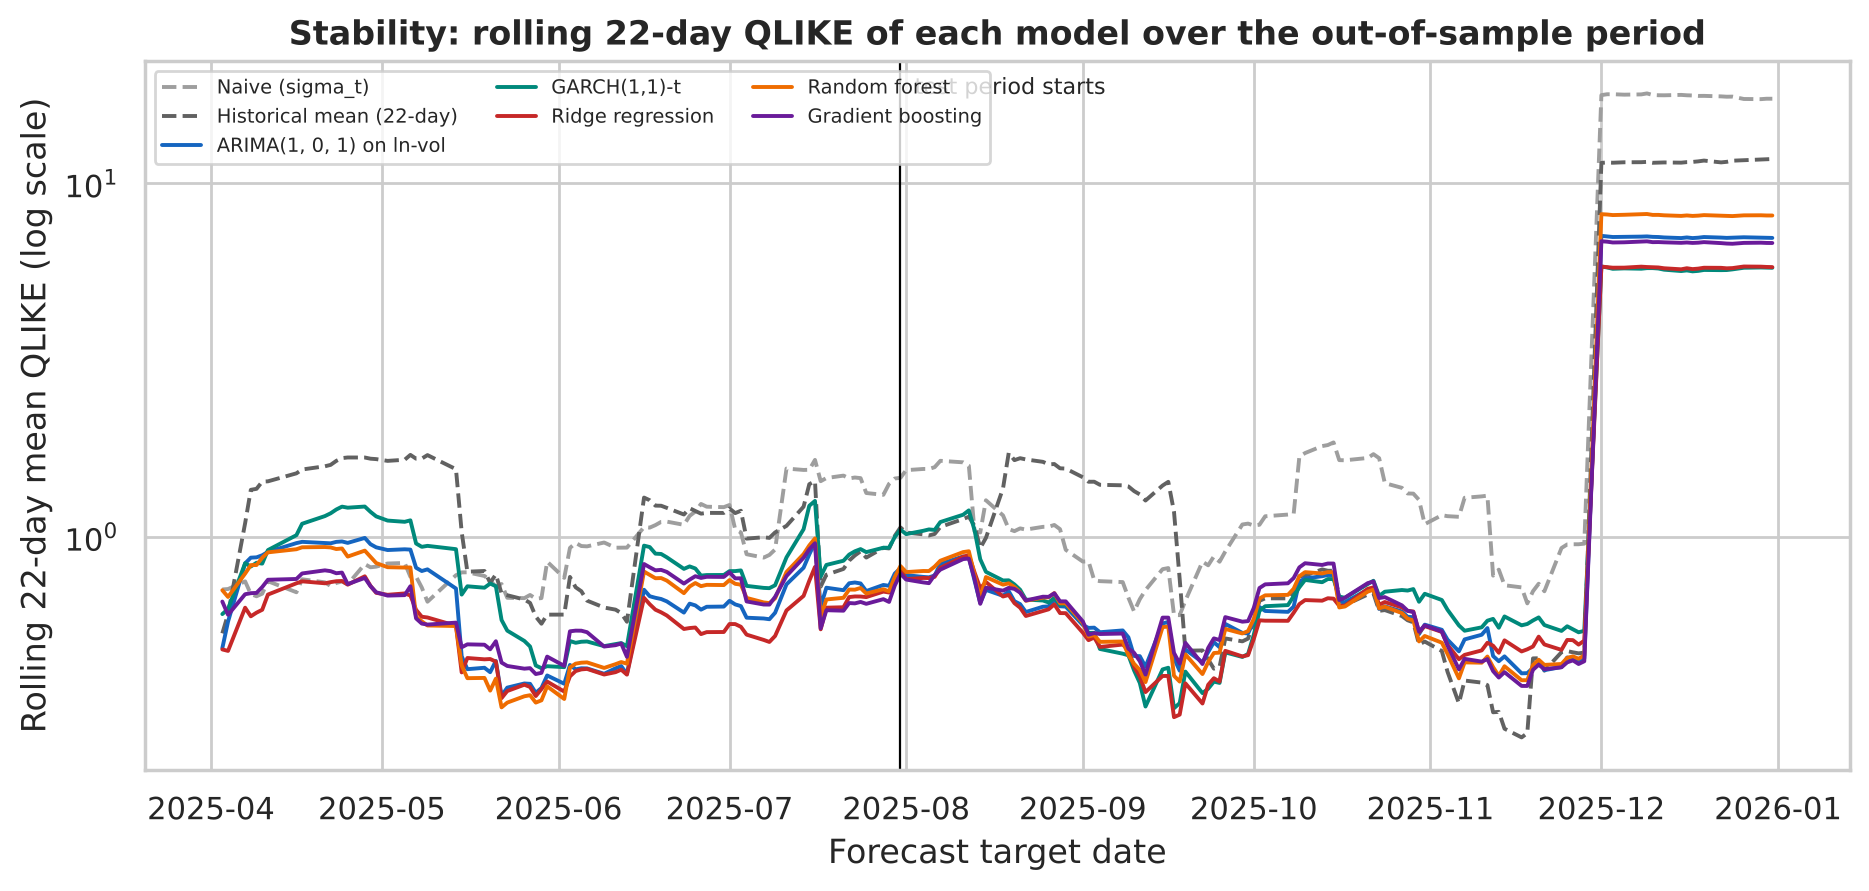

event,Post-Cyclone Ditwah (1-5 Dec 2025),US tariff shock (2-11 Apr 2025)
model,,
"ARIMA(1, 0, 1) on ln-vol",36.7442,1.5576
"GARCH(1,1)-t",29.2698,1.2443
Gradient boosting,35.4059,0.8292
Historical mean (22-day),60.7669,3.0786
Naive (sigma_t),93.3239,0.9437
Random forest,42.6284,1.0594
Ridge regression,29.3945,0.9953


,test QLIKE (all),test QLIKE (excl. 1 Dec),test RMSE (all),test RMSE (excl. 1 Dec),rank (all),rank (excl. 1 Dec)
model,,,,,,
Naive (sigma_t),4.5939,0.9729,1.5116,1.0870,7,7
Historical mean (22-day),3.1400,0.7819,1.2063,0.6099,6,6
"ARIMA(1, 0, 1) on ln-vol",1.9371,0.5043,1.1465,0.5198,4,1
"GARCH(1,1)-t",1.6857,0.5482,1.1493,0.5462,2,5
Ridge regression,1.6584,0.5151,1.1516,0.5508,1,4
Random forest,2.1686,0.5051,1.1515,0.5185,5,2
Gradient boosting,1.8926,0.5115,1.1525,0.5363,3,3


,DM stat (QLIKE),p (QLIKE),DM stat (squared error),p (squared error)
model,,,,
Naive (sigma_t),0.9691,0.3349,0.9815,0.3287
"ARIMA(1, 0, 1) on ln-vol",-2.2536,0.0264,-2.1324,0.0354
"GARCH(1,1)-t",-1.7230,0.0880,-1.2073,0.2302
Ridge regression,-1.9733,0.0512,-1.1225,0.2643
Random forest,-2.1801,0.0316,-1.7982,0.0752
Gradient boosting,-2.1457,0.0343,-1.3811,0.1703


In [16]:
reg, thr = aa.regime_table(res); reg_x, _ = aa.regime_table(res, exclude=["2025-12-01"])
print(f"Regime threshold: {thr:.3f}% daily volatility")
display(reg.pivot(index="model", columns="regime", values="QLIKE"))
display(reg_x.pivot(index="model", columns="regime", values="QLIKE"))
show(aa.fig_regimes(res, reg, reg_x))
roll = aa.rolling_loss(res); show(aa.fig_rolling_loss(res, roll))
display(aa.event_windows(res).pivot(index="model", columns="event", values="QLIKE"))
display(aa.outlier_sensitivity(res))
display(dg.dm_table(res, "Historical mean (22-day)", exclude=["2025-12-01"]))

model,Gradient boosting,Random forest,Ridge regression
feature,,,
lv_1,0.0232,0.0070,0.0434
lv_0,0.0300,0.0110,0.0333
log_trades_0,0.0124,0.0132,0.0289
abn_volume,0.0067,0.0005,0.0221
absret_0,0.0069,0.0172,0.0195
lv_2,0.0001,-0.0003,0.0104
ret_0,0.0128,0.0083,0.0079
lv_w,-0.0010,0.0005,0.0057
days_to_next,-0.0019,0.0025,0.0051


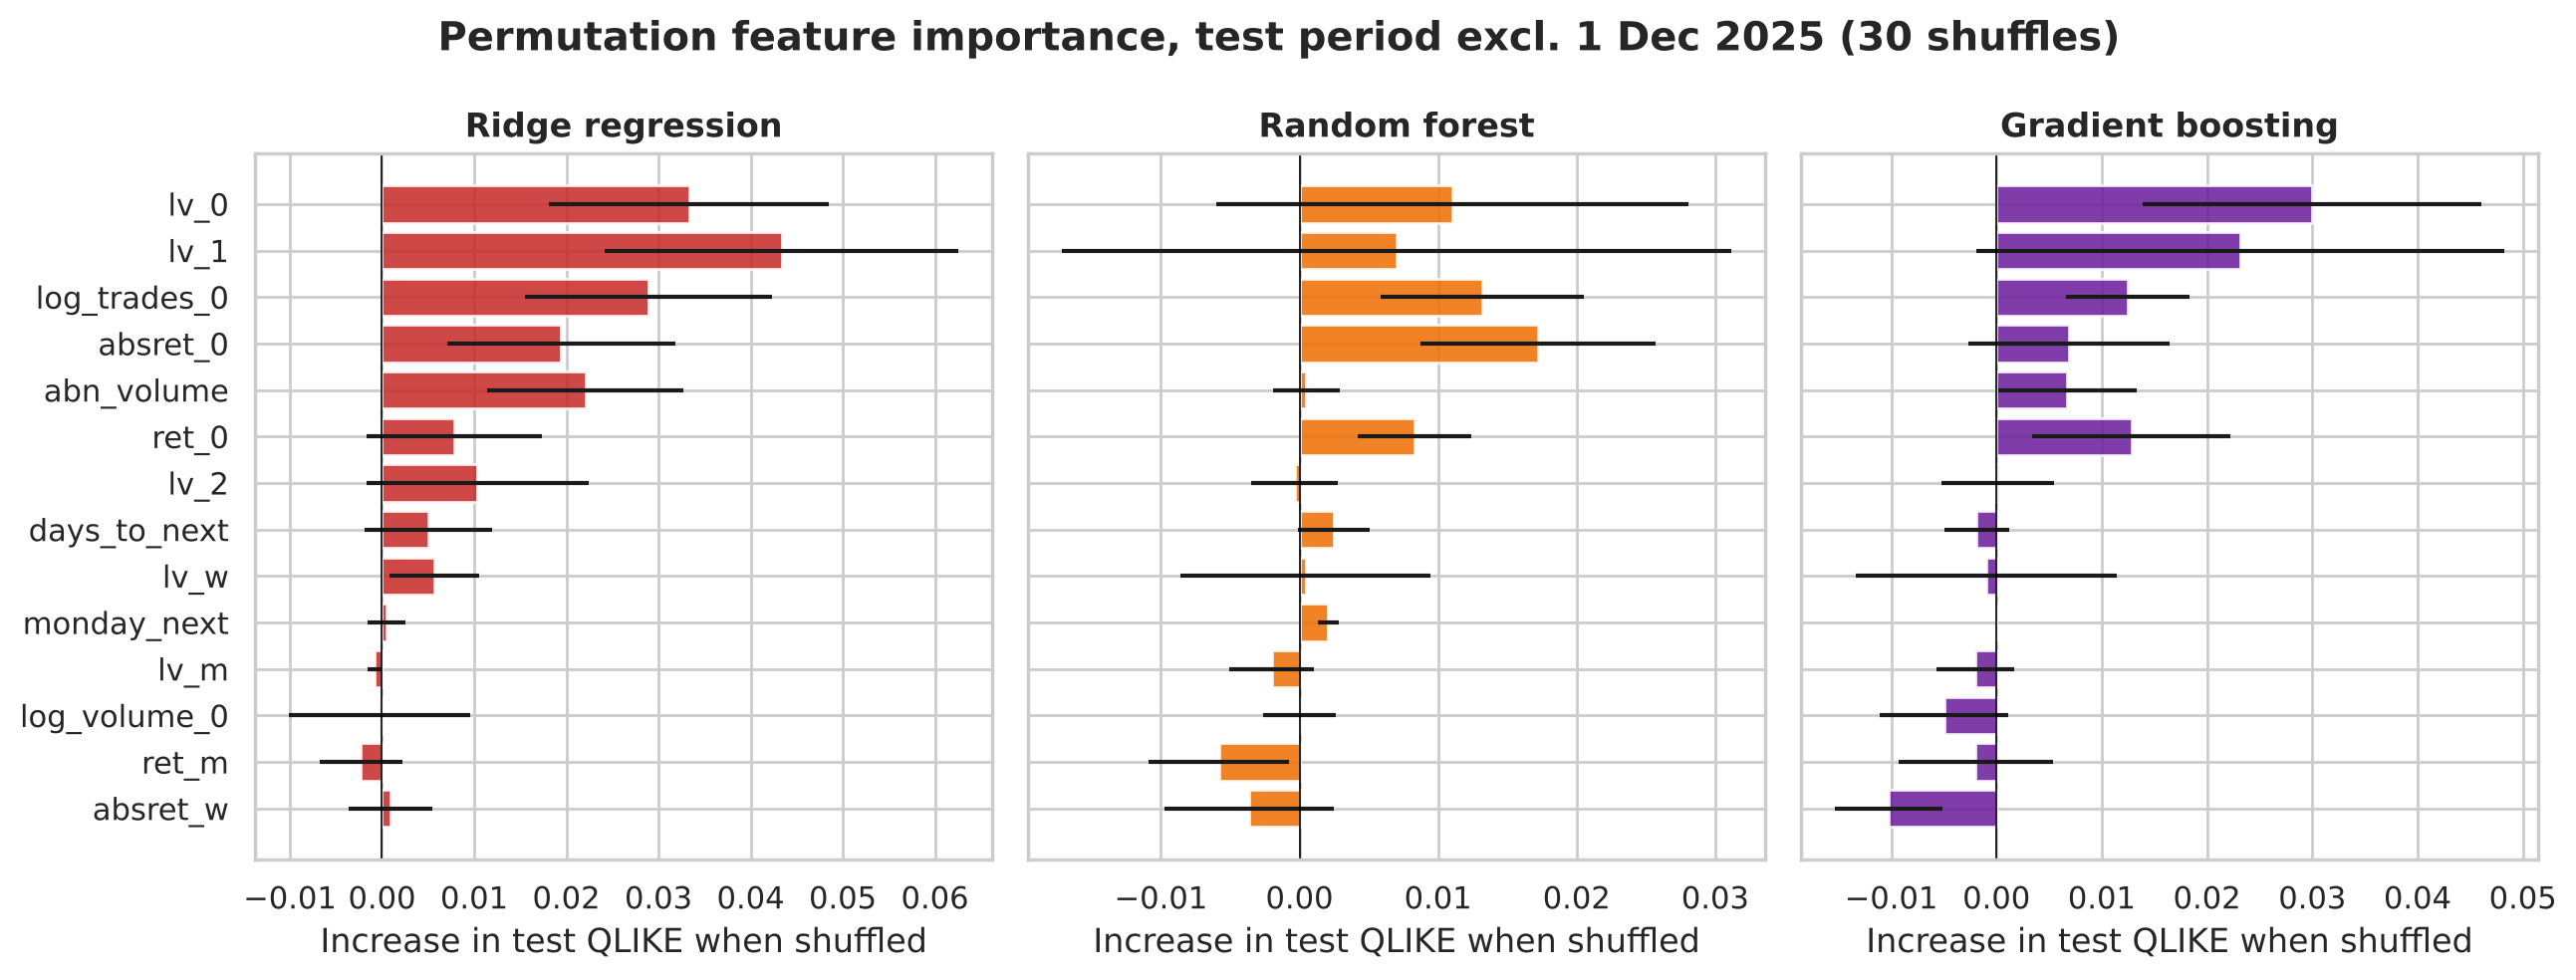

,feature,standardised coefficient,description
0,lv_1,0.1250,log Parkinson volatility on day t-1
1,log_trades_0,0.1249,log of number of trades on day t
2,absret_0,0.1002,absolute adjusted return on day t (size of las...
3,lv_0,0.0958,log Parkinson volatility on day t (most recent...
4,log_volume_0,-0.0780,log of shares traded on day t (activity / liqu...
5,days_to_next,0.0706,calendar days until the next trading day (know...
6,abn_volume,0.0693,log(volume_t / 22-day average volume): unusual...
7,lv_2,0.0635,log Parkinson volatility on day t-2
8,ret_0,-0.0603,signed adjusted return on day t (captures the ...
9,ret_m,-0.0405,cumulative adjusted return over the last 22 da...


In [17]:
imp = aa.permutation_importance(res)
display(imp.pivot(index="feature", columns="model", values="mean QLIKE increase").sort_values("Ridge regression", ascending=False))
show(aa.fig_importance(res, imp))
display(aa.ridge_coefficients(res))

## 10. Robustness: same pipeline on the non-voting share (COMB.X0000)

In [18]:
res_x = run_models("X")
display(dg.comparison_table(res_x)[["approach","val QLIKE","test QLIKE","test RMSE","val rank (QLIKE)","test rank (QLIKE)"]])

[X] ARIMA order by AIC: (1, 0, 1)


[X] GARCH variant by validation QLIKE: GARCH(1,1)-t
[X] Ridge regression best params: {'alpha': np.float64(0.01)}


[X] Random forest best params: {'max_depth': 3, 'min_samples_leaf': 5, 'max_features': np.float64(1.0)}


[X] Gradient boosting best params: {'learning_rate': np.float64(0.02), 'n_estimators': 300, 'max_depth': 2}


,approach,val QLIKE,test QLIKE,test RMSE,val rank (QLIKE),test rank (QLIKE)
model,,,,,,
Naive (sigma_t),Baseline,1.1314,1.1246,0.8030,7,7
Historical mean (22-day),Baseline,1.0966,0.6828,0.7031,6,6
"ARIMA(1, 0, 1) on ln-vol",Traditional,0.8659,0.5277,0.6595,4,4
"GARCH(1,1)-t",Traditional,0.9043,0.5132,0.7169,5,3
Ridge regression,Machine learning,0.7968,0.4839,0.6648,1,2
Random forest,Machine learning,0.8225,0.4697,0.6462,3,1
Gradient boosting,Machine learning,0.8039,0.5434,0.6784,2,5


## 11. Conclusions (see the report for full discussion)
1. Every forecasting model beat both baselines on the test period (QLIKE 31–47% lower than the 22-day historical mean).
2. Traditional and machine-learning models performed **similarly**; Ridge regression ranked first on both validation and test, but
   Diebold–Mariano tests do not show significant differences among the five models.
3. The ranking is **fragile**: it changes when the single 1 Dec 2025 shock is excluded (ARIMA first) and on the non-voting share (Random Forest first).
4. Tree models fit the training data far better than they forecast (train QLIKE ≈ 0.33–0.36 vs validation ≈ 0.66–0.68): overfitting with only ~250 training days.
5. No model anticipated the 1 Dec 2025 shock, which arrived in a *low*-volatility regime — the main practical limitation for risk management.